# DTC – V08682A – final runs for the DTC chapter

Everything needed for the chapter, in order:

1. **Pre-training** (40 epochs): reconstruction, losses, table of the losses.
2. **Scans with the Euclidean metric** (30 epochs), to justify the choices of the final runs:
   - $\gamma = 10, 100, 1000, 10000$ with 2 clusters;
   - 2, 3, 4 clusters with $\gamma = 1000$.
3. **Final runs, ACF / Euclidean / CID** (2 clusters, $\gamma = 1000$, `TRAINING_EPOCHS` epochs, from the **same** pre-trained TAE and seed):
   reconstruction, losses and table, separation in energy and A/E + rise time on training, validation and test set.
4. **Comparison** of the three metrics, with A/E as reference.

All the plots go to `/storage/rasera/DeepTemporalClusteringForL200/finalplots` with no subfolders: the file names start with the
run they belong to (`pretrain_...`, `scan_eucl_gamma1000_...`, `scan_eucl_3cl_...`, `acf_...`, `eucl_...`, `cid_...`).
Every table is shown here and also saved in the same folder as `.csv` and `.tex` (LaTeX `tabular`, ready for `\input`).

**If you re-run the import cell, re-run also the PARAMETERS cell**: importing `preliminary` / `DeepTemporalClustering` reloads `pf`
and resets `PLOT_DIR`, `TAG` and `PREFIX`.

In [1]:
import sys, os
sys.path.append(os.path.abspath('..'))     # common modules live in the main folder

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import importlib

import preliminary
importlib.reload(preliminary)
import plottingfunctions as pf
importlib.reload(pf)
import DeepTemporalClustering as DTC
importlib.reload(DTC)
import loadercreator
importlib.reload(loadercreator)

assert hasattr(pf, 'PREFIX'), "use the plottingfunctions.py with PREFIX (all the plots in one folder)"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("The device I'm using is:", device)
print("wfcleaningNEW in use:", preliminary.wfcleaning.__file__)

The device I'm using is: cuda
wfcleaningNEW in use: /storage/rasera/DeepTemporalClusteringForL200/wfcleaningNEW.py


/storage/rasera/raseraenv/lib/python3.11/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


# SANITY CHECKS

In [2]:
preliminary.sanity_check(use_charge=False)
preliminary.sanity_check(use_charge=True)
preliminary.sanity_check_dtc(use_charge=False)
preliminary.sanity_check_dtc(use_charge=True)

/storage/rasera/raseraenv/lib/python3.11/site-packages/torch/nn/modules/conv.py:304: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at ../aten/src/ATen/native/Convolution.cpp:1031.)
  return F.conv1d(input, weight, bias, self.stride,


use_charge=False
  input shape:         (4, 1, 200)
  latent shape:        (4, 1, 20)  (atteso: (4, 1, 20))
  reconstructed shape: (4, 1, 200)  (atteso: (4, 1, 200))
  loss: 217510592.0000
  parametri senza gradiente: 0 (atteso: 0)
  logvar_obs.grad: [-2.1751195e+08]
  OK

use_charge=True
  input shape:         (4, 2, 200)
  latent shape:        (4, 1, 20)  (atteso: (4, 1, 20))
  reconstructed shape: (4, 2, 200)  (atteso: (4, 2, 200))
  loss: 234953152.0000
  parametri senza gradiente: 0 (atteso: 0)
  logvar_obs.grad: [-2.3338670e+08 -1.5686696e+06]
  OK

use_charge=False
  input shape:         (4, 1, 200)
  reconstructed shape: (4, 1, 200)  (atteso: (4, 1, 200))
  q shape:             (4, 2)  (atteso: (4, 2))
  q.sum(dim=1):        [0.99999994 1.         1.         1.        ]  (atteso: tutti ~1.0)
  numero di tensori allenabili: 24  (atteso: > 0)
  loss: 229431968.0000
  parametri senza gradiente: 0 (atteso: 0)
  clusters.grad è None: False (atteso: False)
  OK

use_charge=True
  inp

# PARAMETERS

In [25]:
# ---------------- data / loaders ----------------
use_charge = False       # True: current + charge (2 channels) | False: current only
normalised = False       # True: corrente normalizzata a 1 evento per evento | False: corrente con ampiezza (A/E)
use_sigma  = False       # True: solo gli eventi nelle finestre SSE (DEP) e MSE (FEP) | False: tutta la finestra 1550-1650 keV
scale      = True        # True: corrente divisa per la mediana dei massimi del training set | False: nessuna scala

# ---------------- pre-training ----------------
PRETRAINING_EPOCHS = 50

# ---------------- choices of the final runs ----------------
N_CLUSTERS      = 2
GAMMA           = 1000
TRAINING_EPOCHS = 100           # final runs of the three metrics (still to be decided)
SEED            = 0            # same seed for every run: same KMeans start, same batch order

# ---------------- scans (Euclidean metric) ----------------
SCAN_METRIC   = 'eucl'
SCAN_EPOCHS   = 20
SCAN_GAMMAS   = [10000]      # with N_CLUSTERS clusters 10, 100, 1000, 
SCAN_CLUSTERS = [2, 3, 4]                   # with GAMMA

# pf.TAG -> name of the metric in DTC (pf.TAG gives the color of the metric in the plots)
METRICS = {'acf': 'acf', 'eucl': 'euclidean', 'cid': 'cid'}
NAMES   = {'acf': 'ACF', 'eucl': 'Euclidean', 'cid': 'CID'}

# ---------------- output ----------------
pf.PLOT_DIR = "/storage/rasera/DeepTemporalClusteringForL200/finalplots"   # plots AND tables, no subfolders
pf.TAG, pf.PREFIX = '', ''
TABLE_DIR = pf.PLOT_DIR
OUT_DIR   = "finalmodels"                                                  # weights and bundles of the final runs
os.makedirs(pf.PLOT_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# PRELIMINARY
Data loading, cleaning and loaders creation.

Periods to process: ['p03', 'p04', 'p05', 'p06', 'p07', 'p08', 'p09']
Period p03: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p04: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p05: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p06: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p07: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p08: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p09: checkpoint loaded from /storage/rasera/clean_data_V08682A
Totale su 7 periodi: 349002 eventi (116985 dopo il taglio A/E)
Waveforms shape (all periods): (349002, 1400)
Energy shape (all periods): (349002,)
Amplitude vs Energy shape (all periods): (349002,)
Rise time shape (all periods): (349002,)
Waveforms shape after AoE cut (all periods): (116985, 1400)
Energy shape after AoE cut (all periods): (116985,)
Rise time shape after AoE cut (all periods): (116985,)
wfcleaningNEW in use: /storage/ras

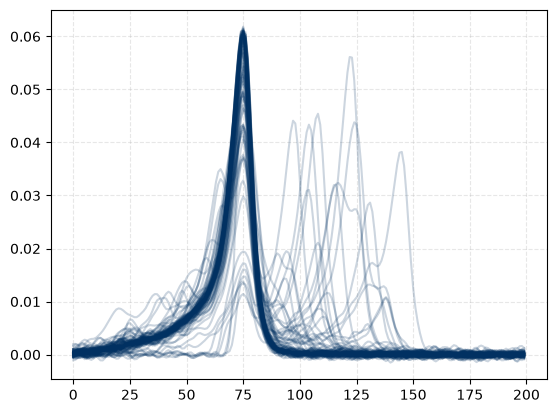

Charge aligned: (348999, 200)
Current aligned: (348999, 200)
Kept: 348999 | noise: 3 | edge: 0 | total: 349002
rise time (all events): 348999 events | NaN/inf: 0 | <= 0: 0
  mean rise time [ns]: 619.1 | median [ns]: 544.0
Charge AoE aligned: (116984, 200)
Current AoE aligned: (116984, 200)
Kept: 116984 | noise: 1 | edge: 0 | total: 116985
rise time (after A/E cut): 116984 events | NaN/inf: 0 | <= 0: 0
  mean rise time [ns]: 517.7 | median [ns]: 528.0
corrente: mediana su 50 punti 0.000456 | mediana su 10 punti 0.000314
carica: mediana su 50 punti 0.004501 | mediana su 10 punti 0.001448
use_charge: False | use_sigma: False | normalised: False | scale: True (scale factor = 0.05650758299488506) | scale_charge: False (charge scale factor = 1.0)
waves: (348999, 1, 200) | NaN/inf: 0
rumore corrente su questa scala (current_noise): 0.008069798057257726
rumore carica su questa scala (charge_noise):   0.004500837161356608
correlazione altezza picco - A/E: 0.9908282813347021
train: 279199 | val:

In [4]:
raw   = preliminary.load_data(chosen_detector="V08682A", e_min=1550, e_max=1650, output_dir="/storage/rasera/clean_data_V08682A")
clean = preliminary.clean_data(raw)
train_loader, validation_loader, all_loader, data = preliminary.create_loaders(clean, use_charge=use_charge, normalised=normalised, use_sigma=use_sigma, scale=scale)

### DEP and FEP windows
Gaussian fits on the clustered events, windows at $\pm 3\sigma$: used to find the SSE-like cluster of every run and in the tables.

In [5]:
energy = data['energy']     # same events, same order, as the cluster assignments (all_loader)

dep, _ = loadercreator.gaussian(energy, xmin=1587, xmax=1598)
fep, _ = loadercreator.gaussian(energy, xmin=1615, xmax=1626)
in_dep = np.abs(energy - dep[1]) <= 3 * dep[2]
in_fep = np.abs(energy - fep[1]) <= 3 * fep[2]

print(f"DEP: mu = {dep[1]:.2f} keV, sigma = {dep[2]:.2f} keV -> {in_dep.sum()} events in the window")
print(f"FEP: mu = {fep[1]:.2f} keV, sigma = {fep[2]:.2f} keV -> {in_fep.sum()} events in the window")

DEP: mu = 1592.40 keV, sigma = 2.10 keV -> 59254 events in the window
FEP: mu = 1620.34 keV, sigma = 2.33 keV -> 95364 events in the window


### Tables
Every table is shown and saved in `TABLE_DIR` as `.csv` and as a LaTeX `tabular` (`.tex`).

In [6]:
def _latex_escape(text):
    for a, b in (('\\', r'\textbackslash{}'), ('%', r'\%'), ('_', r'\_'), ('&', r'\&'), ('#', r'\#')):
        text = text.replace(a, b)
    return text


def save_table(df, name, decimals=2):
    """Show the table and save it as TABLE_DIR/name.csv and TABLE_DIR/name.tex."""
    display(df.round(decimals))
    df.to_csv(os.path.join(TABLE_DIR, name + '.csv'))
    fmt = lambda v: f"{v:.{decimals}f}" if isinstance(v, (float, np.floating)) else _latex_escape(str(v))
    header = [_latex_escape(str(df.index.name or ''))] + [_latex_escape(str(c)) for c in df.columns]
    lines = [r'\begin{tabular}{l' + 'r' * len(df.columns) + '}', r'\hline', ' & '.join(header) + r' \\', r'\hline']
    for idx, row in df.iterrows():
        lines.append(' & '.join([fmt(idx)] + [fmt(v) for v in row]) + r' \\')
    lines += [r'\hline', r'\end{tabular}']
    with open(os.path.join(TABLE_DIR, name + '.tex'), 'w') as fh:
        fh.write('\n'.join(lines) + '\n')
    print("saved:", os.path.join(TABLE_DIR, name + '.csv'), "|", name + '.tex')

# 1. PRE-TRAINING
Once, shared by every run of this notebook. Plots: `pretrain_reconstruction.pdf`, `pretrain_losses.pdf`.

initial sigma of the NLL: 0.00807
Pretraining on the device: cuda
[pretrain] epoch 1/50 - train: 860.0076  val: -536.8151
[pretrain] epoch 2/50 - train: -618.9187  val: -678.3420
[pretrain] epoch 3/50 - train: -708.3997  val: -735.0067
[pretrain] epoch 4/50 - train: -746.1065  val: -755.7333
[pretrain] epoch 5/50 - train: -758.8108  val: -758.2921
[pretrain] epoch 6/50 - train: -765.0516  val: -768.3022
[pretrain] epoch 7/50 - train: -769.8336  val: -770.9751
[pretrain] epoch 8/50 - train: -773.7063  val: -776.4228
[pretrain] epoch 9/50 - train: -776.7039  val: -777.8133
[pretrain] epoch 10/50 - train: -779.1713  val: -781.8480
[pretrain] epoch 11/50 - train: -781.0167  val: -783.4522
[pretrain] epoch 12/50 - train: -782.7251  val: -785.1189
[pretrain] epoch 13/50 - train: -784.2429  val: -785.1024
[pretrain] epoch 14/50 - train: -785.4078  val: -787.6277
[pretrain] epoch 15/50 - train: -786.5136  val: -788.8626
[pretrain] epoch 16/50 - train: -787.7169  val: -787.9677
[pretrain] epoch

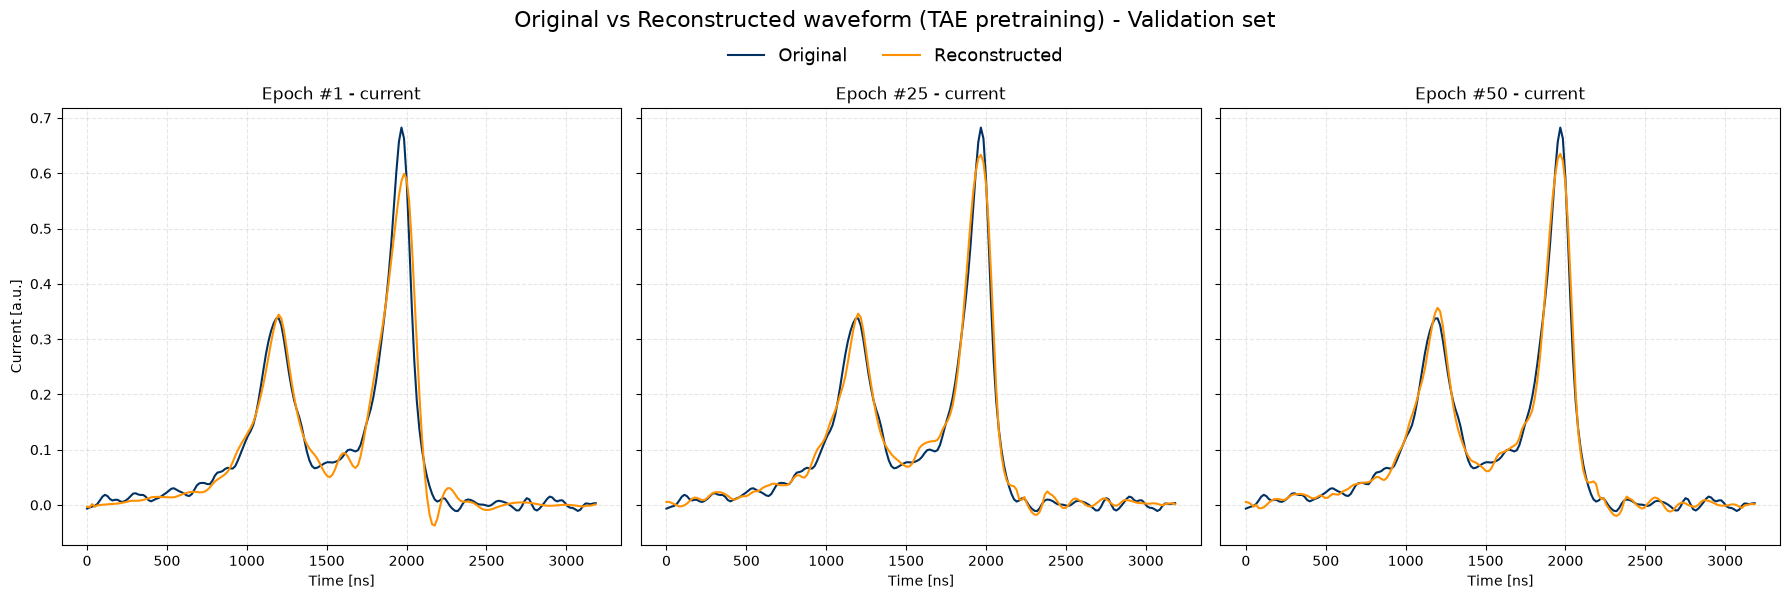

saved: /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/tae_pretrained_50ep.pth


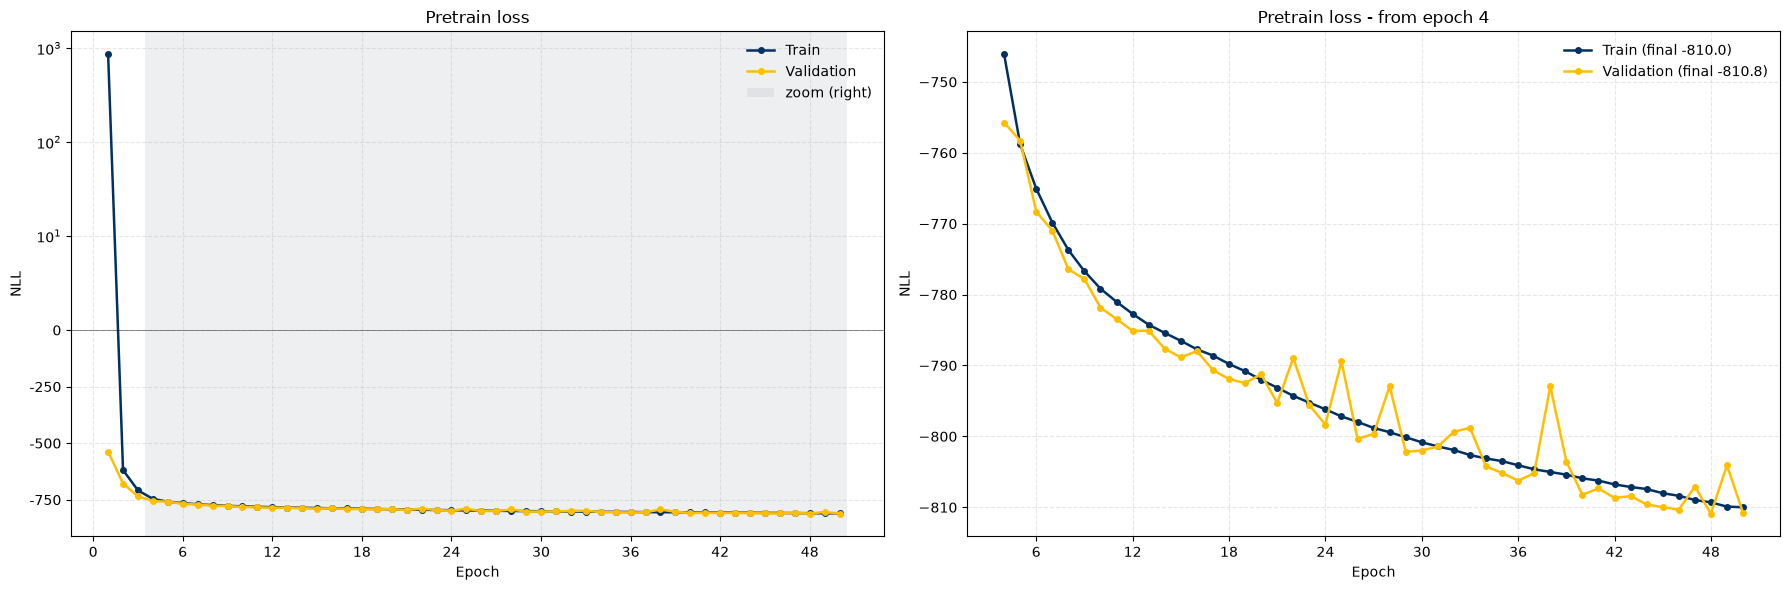

In [7]:
TAE_PATH = os.path.join(OUT_DIR, f"tae_pretrained_{PRETRAINING_EPOCHS}ep.pth")

torch.manual_seed(42)
dtc = DTC.DTC(input_length=data['waves'].shape[-1], pool_size=10, n_clusters=N_CLUSTERS, use_charge=use_charge)

# noise of the NLL initialised from the data (baseline of the training waveforms, on the scale fed to the network)
noise = np.median(np.std(data['waves'][data['idx_train'], 0, :20], axis=1))
with torch.no_grad():
    dtc.tae.logvar_obs.fill_(float(np.log(noise ** 2)))
print(f"initial sigma of the NLL: {noise:.5f}")

pf.TAG, pf.PREFIX = '', ''
pre_train_l, pre_val_l = DTC.pretrain(dtc.tae, train_loader, validation_loader, epochs=PRETRAINING_EPOCHS)

torch.save(dtc.tae.state_dict(), TAE_PATH)
print("saved:", os.path.abspath(TAE_PATH))

pf.plot_pretrain_losses(pre_train_l, pre_val_l)

#### Table: pre-training losses

In [8]:
pre_table = pd.DataFrame({'NLL train': pre_train_l, 'NLL validation': pre_val_l},
                         index=pd.Index(np.arange(1, len(pre_train_l) + 1), name='epoch'))
save_table(pre_table, 'table_pretrain_losses')

,NLL train,NLL validation
epoch,,
1,860.01,-536.82
2,-618.92,-678.34
3,-708.40,-735.01
4,-746.11,-755.73
5,-758.81,-758.29
6,-765.05,-768.30
7,-769.83,-770.98
8,-773.71,-776.42
9,-776.70,-777.81


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_pretrain_losses.csv | table_pretrain_losses.tex


# 2. DTC TRAINING – common functions
Every run reloads the **same** pre-trained TAE, freezes `logvar_obs`, initialises the clusters with KMeans and rewinds the shuffle
with the **same** seed: two runs differ only in what is changed on purpose (metric, $\gamma$, number of clusters).

In [9]:
def cluster_run(n_clusters, distance_metric, gamma, epochs, weights=TAE_PATH, seed=SEED):
    
    torch.manual_seed(seed)
    
    assert train_loader.generator is not None, \
        "train_loader va ricostruito con epoch_loader(..., seed=...) perché questo funzioni"
    train_loader.generator.manual_seed(seed)   # riavvolge lo shuffle: indipendente da quante corse ci sono state prima
    
    model = DTC.DTC(input_length=data['waves'].shape[-1], pool_size=10, n_clusters=n_clusters,
                    distance_metric=distance_metric, use_charge=use_charge)
    model.tae.load_state_dict(torch.load(weights, map_location="cpu", weights_only=True))
    model.tae.logvar_obs.requires_grad_(False)
    
    DTC.initialization_of_clusters_weights(model, train_loader, seed=seed)
    dev = next(model.parameters()).device
    y_init = DTC.cluster_assignments(model, all_loader, dev)
    
    model, tr, va, frac, chg = DTC.training(model, train_loader, validation_loader, epochs=epochs, gamma=gamma)
    y_after = DTC.cluster_assignments(model, all_loader, dev)
    
    print(f"[{distance_metric}, gamma={gamma}, {n_clusters} clusters] events that changed cluster with the training: "
          f"{(y_init != y_after).mean():.4f}")
    return dict(model=model, y_init=np.asarray(y_init), y=np.asarray(y_after), total_train=tr, total_val=va,
                gamma=gamma, n_clusters=n_clusters, metric=distance_metric)


def training_table(run):
    """Losses of every epoch of a DTC run."""
    h = run['model'].history
    frac = ['/'.join(f"{x:.2f}" for x in np.ravel(f)) for f in h['fractions']]
    return pd.DataFrame({'total train': run['total_train'], 'total validation': run['total_val'],
                         'NLL train': h['nll_train'], 'NLL validation': h['nll_val'],
                         'KL train': h['kl_train'], 'KL validation': h['kl_val'],
                         'changes [%]': 100 * np.asarray(h['changes']),
                         'events per cluster': frac},
                        index=pd.Index(np.arange(1, len(run['total_train']) + 1), name='epoch'))


def composition(y, n_clusters, mask=None):
    """Fraction of the events of every cluster, and fraction of the DEP / FEP events in every cluster."""
    m = np.ones(len(y), bool) if mask is None else np.zeros(len(y), bool)
    if mask is not None:
        m[mask] = True
    size = [float((y[m] == k).mean()) for k in range(n_clusters)]
    dep_f = [float((y[m & in_dep] == k).mean()) for k in range(n_clusters)]
    fep_f = [float((y[m & in_fep] == k).mean()) for k in range(n_clusters)]
    return size, dep_f, fep_f


def sse_like(y, n_clusters):
    """SSE-like cluster: the one with the largest (DEP fraction - FEP fraction), on all the events."""
    _, dep_f, fep_f = composition(y, n_clusters)
    return int(np.argmax(np.array(dep_f) - np.array(fep_f)))


def plot_energy_and_history(run, prefix, label):
    """Training history + clusters vs energy on the whole calibration dataset (used by the scans)."""
    pf.PREFIX = prefix
    k = run['n_clusters']
    pf.plot_training_history(run['model'].history, name=f"{k}cl_training_history")
    pf.plot_clusters_vs_energy(run['y'], energy, k, title=f"{pf._title(k, 'all', len(energy))} - {label}",
                               name=f"{k}cl_energy_all", colors=pf.cluster_colors(run['y'], energy, k))

# 2a. SCAN OF $\gamma$ (Euclidean, 30 epochs, 2 clusters)
For every $\gamma$: reconstruction after the training, training history, clusters vs energy on the whole calibration dataset
(files `scan_eucl_gamma<γ>_...`). Then one summary table.

$\gamma$ is chosen with **unsupervised** criteria (reconstruction not degraded, assignments that move away from KMeans and then
stabilise); the DEP/FEP columns are shown as a check, not used for the choice.

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans
Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.882 0.118]
[train] epoch 1/20 - train: 69.4746  val: 91.5604  events per cluster: [0.514 0.486]  changes: 0.3681
        NLL: -595.91   KL: 0.0665
[train] epoch 2/20 - train: 63.3045  val: 28.5882  events per cluster: [0.578 0.422]  changes: 0.0646
        NLL: -636.48   KL: 0.0700
[train] epoch 3/20 - train: 24.0651  val: 62.0928  events per cluster: [0.475 0.525]  changes: 0.1026
        NLL: -658.67   KL: 0.0683
[train] epoch 4/20 - train: 10.5014  val: -11.8875  events per cluster: [0.579 0.421]  changes: 0.1037
        NLL: -667.69   KL: 0.0678
[train] epoch 5/20 - train: -445.4875  val: 163.6867  events per cluster: [0.571 0.429]  changes: 0.0397
        NLL: -694.37   KL: 0.0249
[train] epoch 6/20 - train: 37.1012  val: 10.3181  events per cluster: [0.538 0.462]  changes: 0.0474
        NLL: -650.42   KL

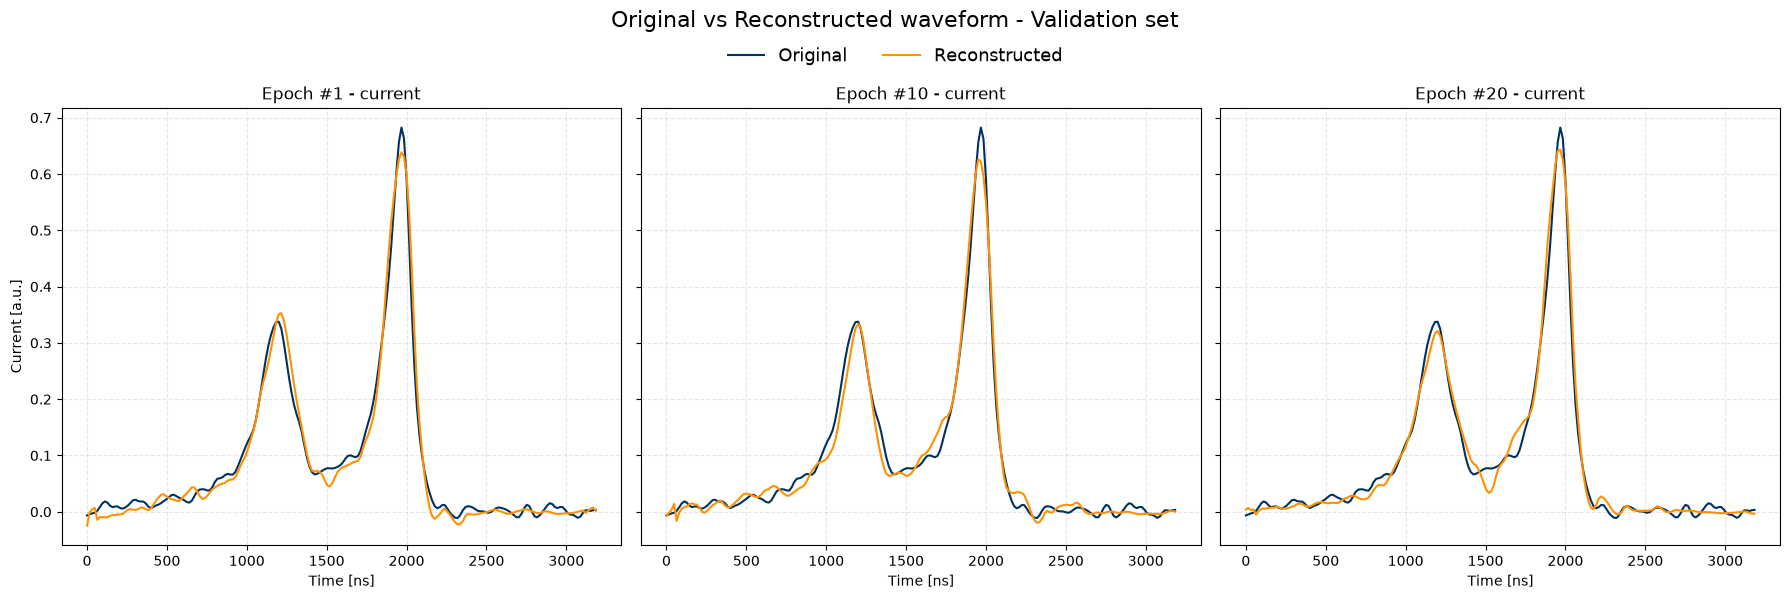

[euclidean, gamma=10000, 2 clusters] events that changed cluster with the training: 0.3314


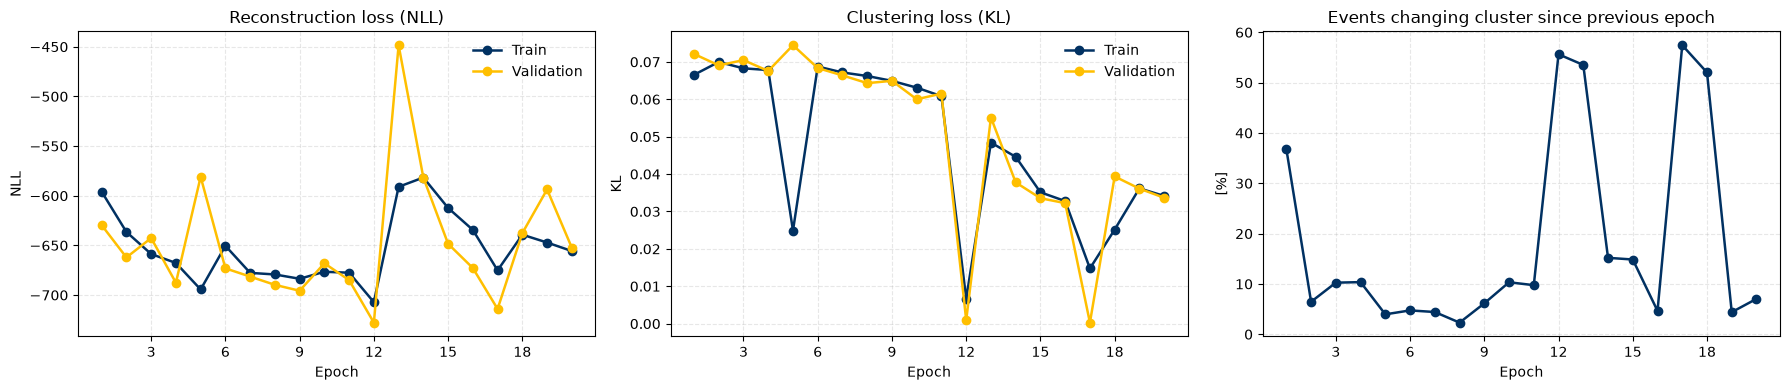

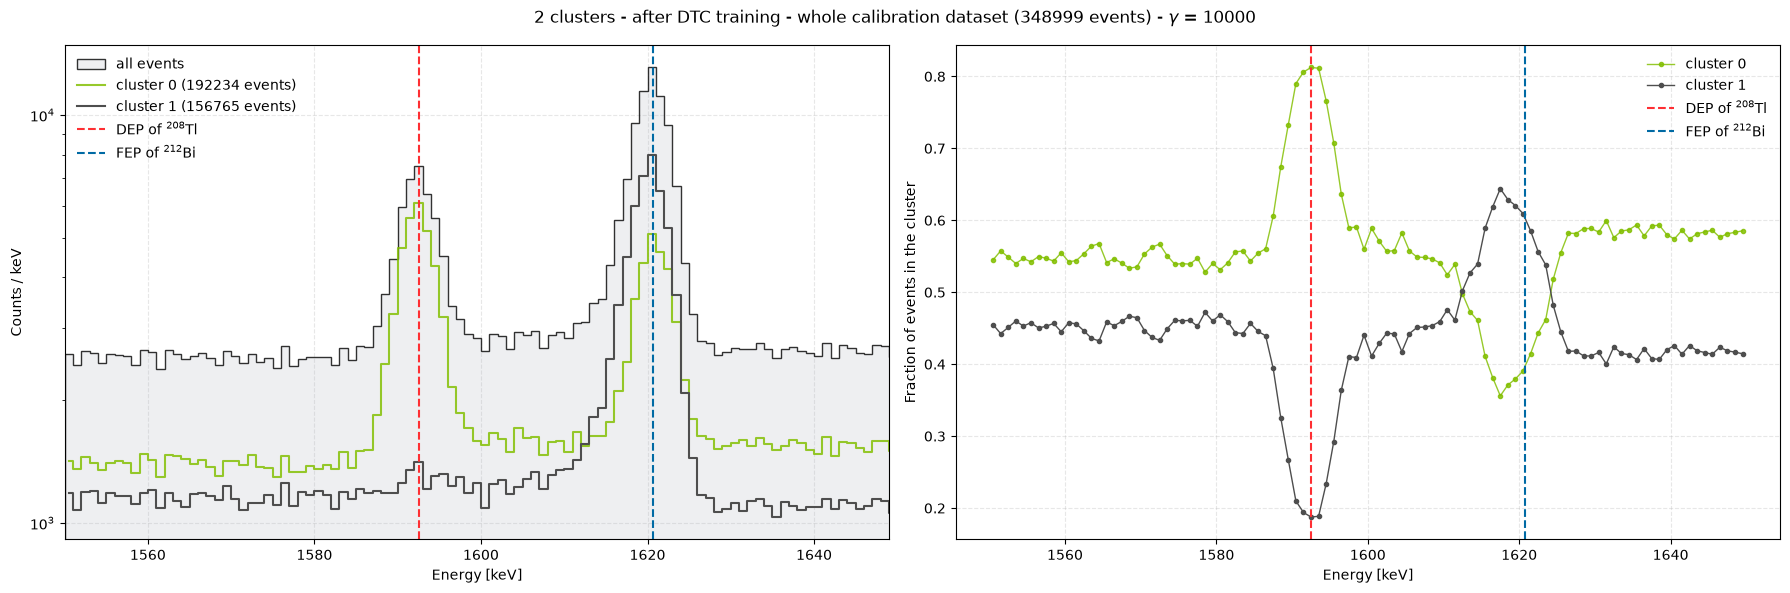

In [26]:
pf.TAG = SCAN_METRIC
scan_gamma = {}
for g in SCAN_GAMMAS:
    pf.PREFIX = f"scan_{SCAN_METRIC}_gamma{g}_"           # also the reconstruction plot made inside DTC.training
    scan_gamma[g] = cluster_run(N_CLUSTERS, METRICS[SCAN_METRIC], gamma=g, epochs=SCAN_EPOCHS)
    plot_energy_and_history(scan_gamma[g], pf.PREFIX, label=f"$\\gamma$ = {g}")

In [11]:
rows = []
for g, r in scan_gamma.items():
    h, y = r['model'].history, r['y']
    s = sse_like(y, N_CLUSTERS)
    keep = y == s
    rows.append({'gamma': g,
                 'NLL validation': h['nll_val'][-1],
                 'NLL change vs pretrain': h['nll_val'][-1] - pre_val_l[-1],
                 'KL validation': h['kl_val'][-1],
                 'gamma x KL': g * h['kl_val'][-1],
                 'moved from KMeans [%]': 100 * (r['y_init'] != y).mean(),
                 'changes last epoch [%]': 100 * h['changes'][-1],
                 'SSE-like kept [%]': 100 * keep.mean(),
                 'DEP kept [%]': 100 * keep[in_dep].mean(),
                 'FEP kept [%]': 100 * keep[in_fep].mean()})
save_table(pd.DataFrame(rows).set_index('gamma'), f'table_scan_{SCAN_METRIC}_gamma')

,NLL validation,NLL change vs pretrain,KL validation,gamma x KL,moved from KMeans [%],changes last epoch [%],SSE-like kept [%],DEP kept [%],FEP kept [%]
gamma,,,,,,,,,
10,-815.97,-5.18,0.01,0.11,4.82,0.06,93.04,95.64,92.32
100,-816.04,-5.25,0.01,1.38,4.25,0.08,92.47,95.31,91.67
1000,-790.69,20.10,0.08,75.57,38.20,1.50,50.06,70.36,35.44
10000,-626.17,184.62,0.00,6.95,12.10,59.28,0.32,0.39,0.17


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_scan_eucl_gamma.csv | table_scan_eucl_gamma.tex


# 2b. SCAN OF THE NUMBER OF CLUSTERS (Euclidean, 30 epochs, $\gamma$ = 1000)
Files `scan_eucl_<K>cl_...`. The run with `N_CLUSTERS` clusters and `GAMMA` is taken from the $\gamma$ scan, not trained again.
Tables: losses per number of clusters, and composition of every cluster (size, fraction of the DEP and of the FEP events).

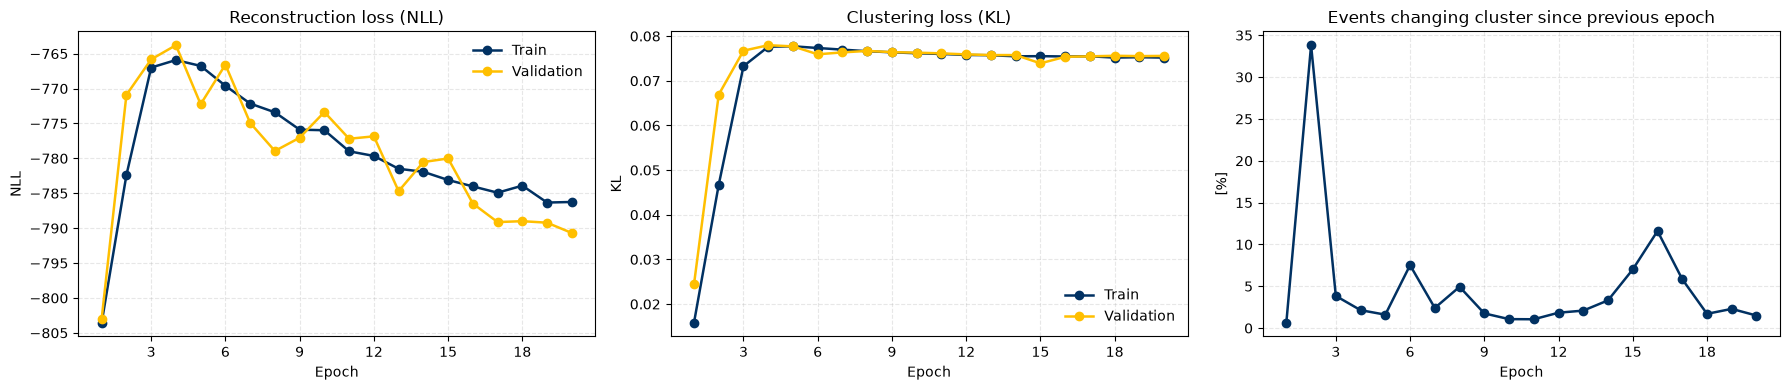

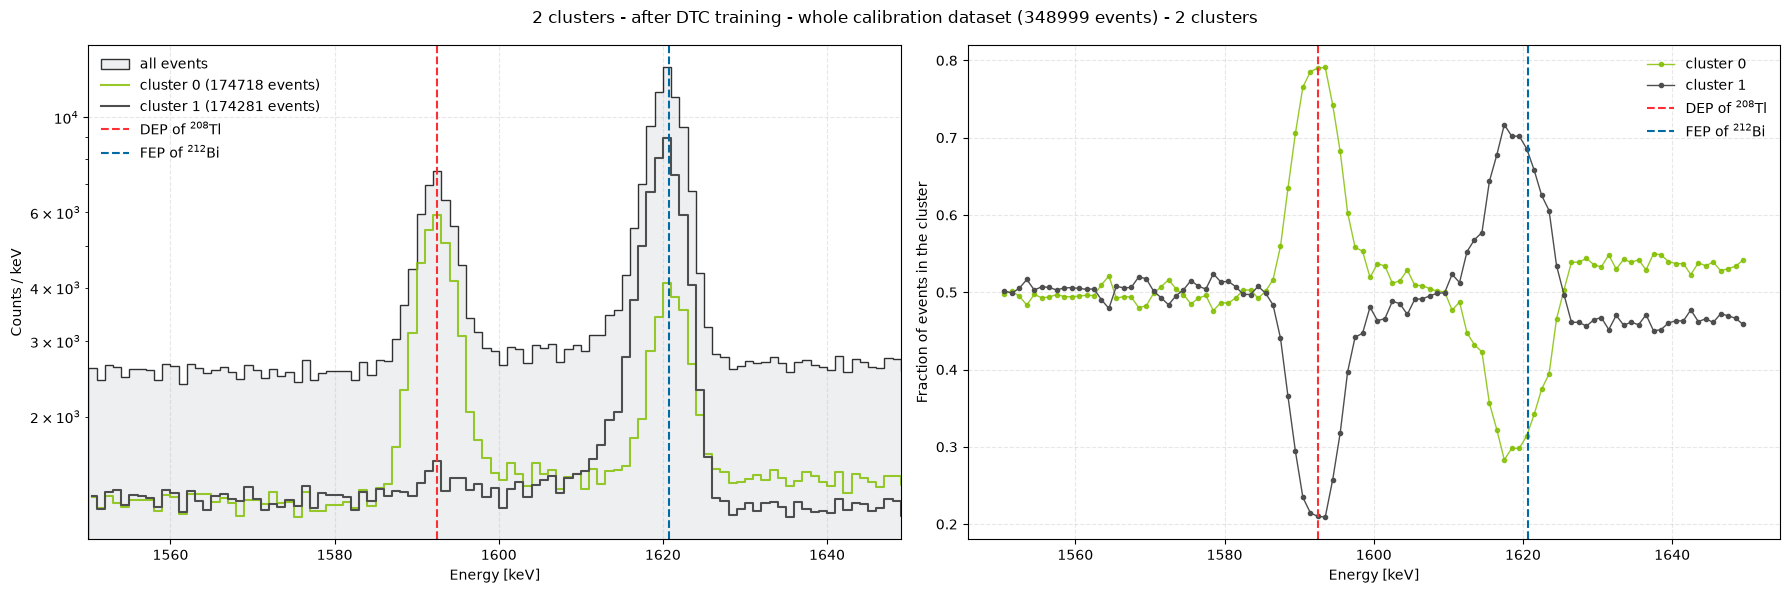

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans
Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.776 0.064 0.16 ]
[train] epoch 1/20 - train: -787.2114  val: -777.1756  events per cluster: [0.    0.215 0.785]  changes: 0.9109
        NLL: -803.76   KL: 0.0165
[train] epoch 2/20 - train: -737.3205  val: -707.1102  events per cluster: [0.    0.499 0.501]  changes: 0.2834
        NLL: -783.63   KL: 0.0463
[train] epoch 3/20 - train: -695.8783  val: -694.0378  events per cluster: [0.    0.503 0.497]  changes: 0.0116
        NLL: -767.97   KL: 0.0721
[train] epoch 4/20 - train: -688.9624  val: -651.8559  events per cluster: [0.    0.474 0.526]  changes: 0.0297
        NLL: -766.44   KL: 0.0775
[train] epoch 5/20 - train: -688.9451  val: -694.4290  events per cluster: [0.    0.513 0.487]  changes: 0.0394
        NLL: -766.74   KL: 0.0778
[train] epoch 6/20 - train: -691.9343  val: -616.9059  events per cluster: 

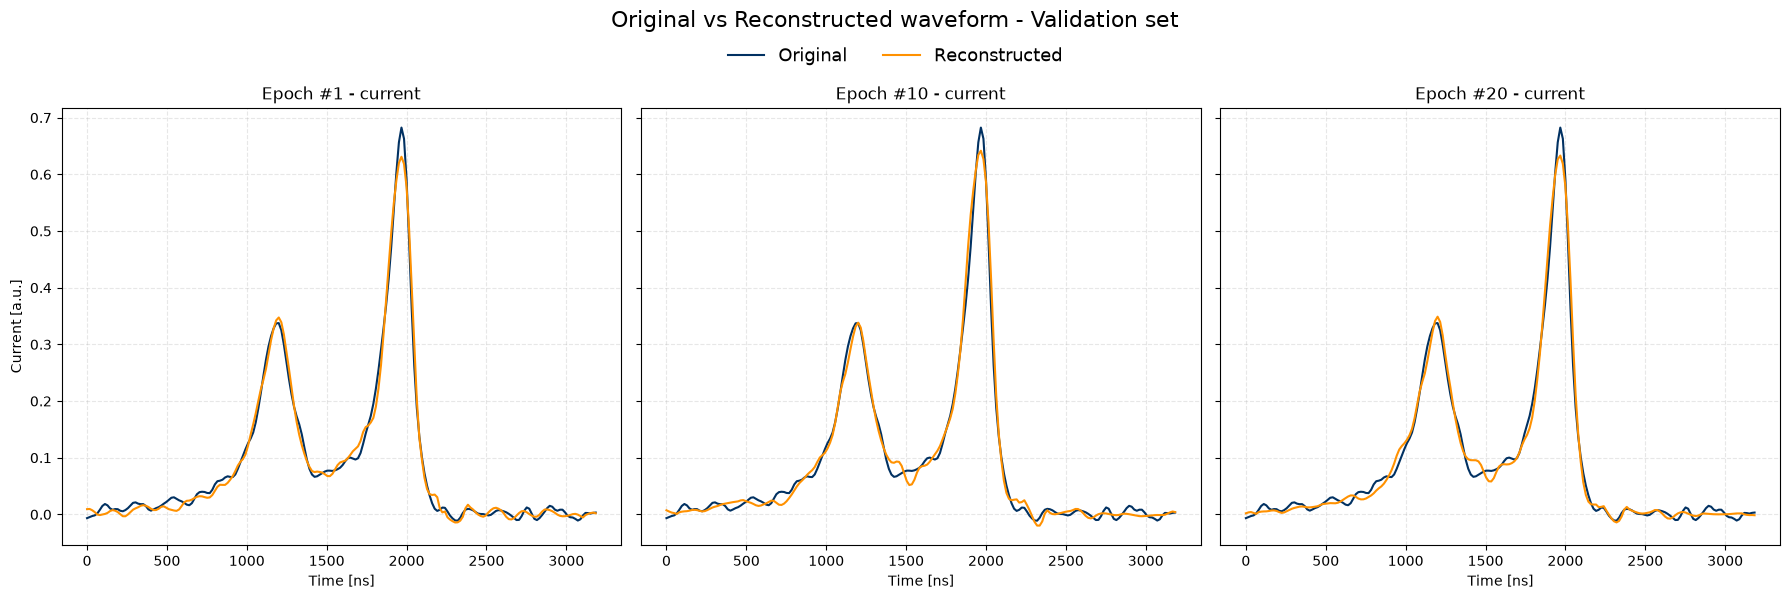

[euclidean, gamma=1000, 3 clusters] events that changed cluster with the training: 0.9356


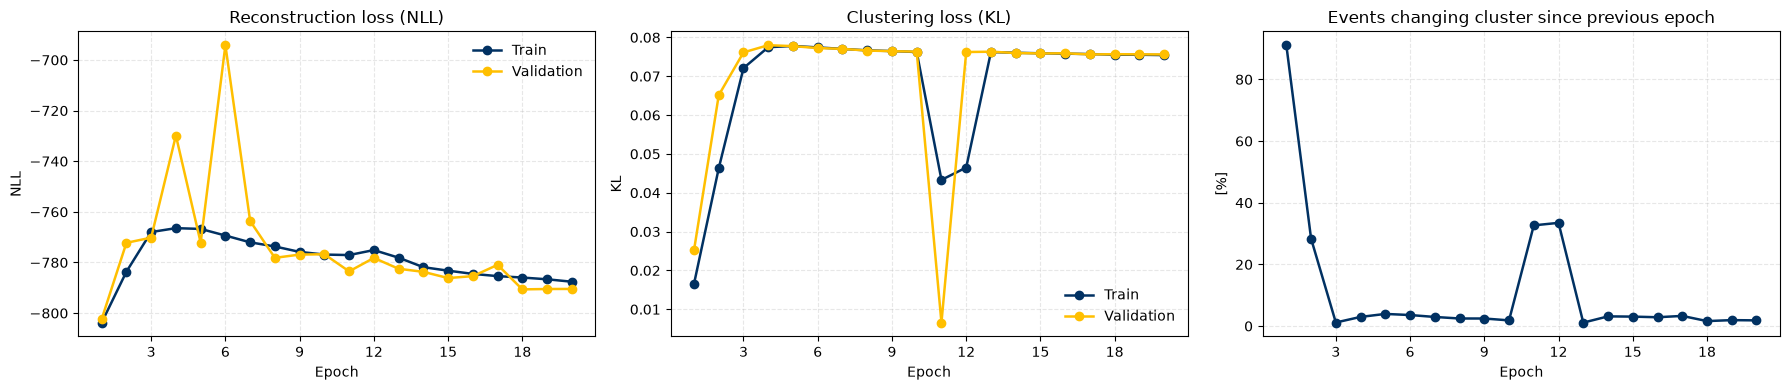

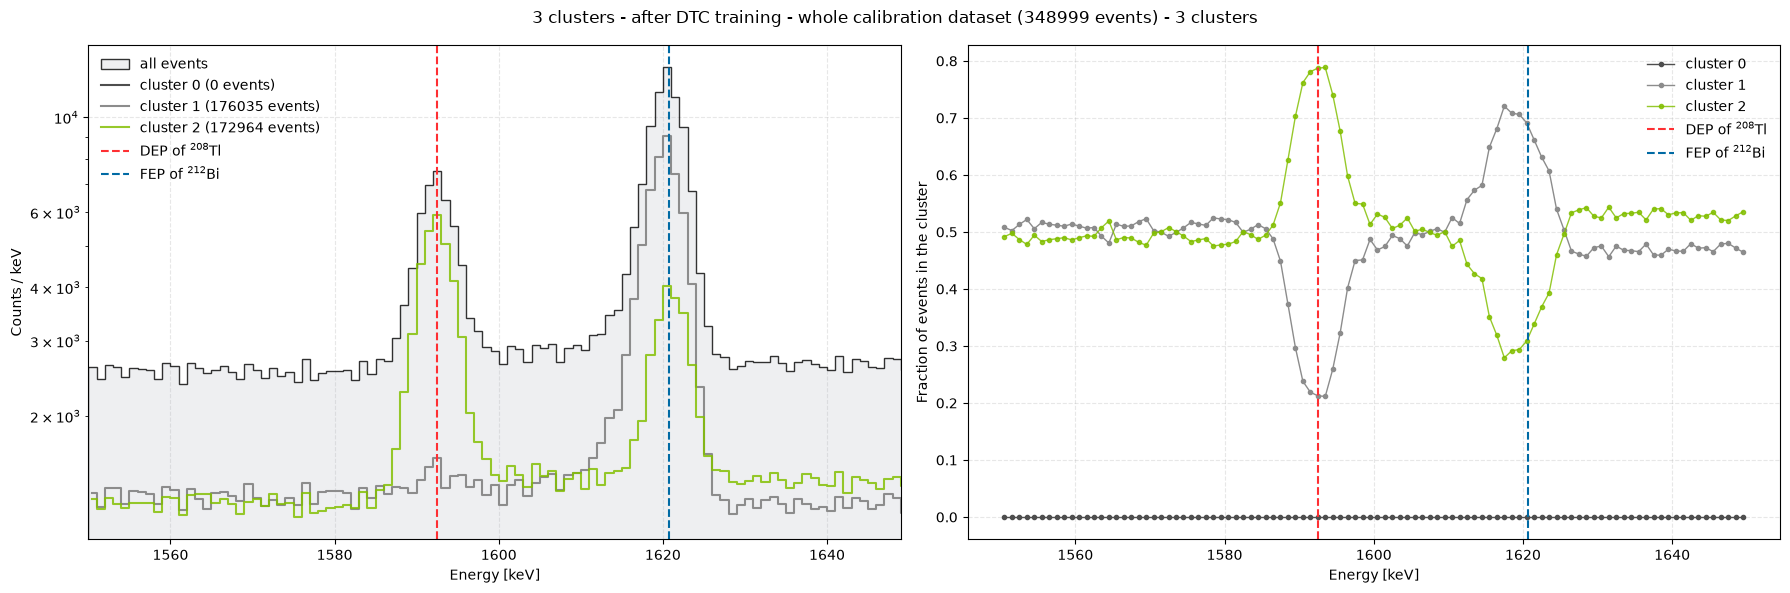

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans
Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.26  0.091 0.603 0.046]
[train] epoch 1/20 - train: -787.7137  val: -778.5272  events per cluster: [0.063 0.117 0.816 0.005]  changes: 0.2686
        NLL: -803.57   KL: 0.0159
[train] epoch 2/20 - train: -736.1431  val: -702.6492  events per cluster: [0.539 0.001 0.    0.46 ]  changes: 0.9897
        NLL: -782.66   KL: 0.0465
[train] epoch 3/20 - train: -693.3360  val: -694.3132  events per cluster: [0.    0.513 0.486 0.001]  changes: 0.9982
        NLL: -766.56   KL: 0.0732
[train] epoch 4/20 - train: -687.6795  val: -655.2899  events per cluster: [0.    0.498 0.495 0.006]  changes: 0.0166
        NLL: -765.30   KL: 0.0776
[train] epoch 5/20 - train: -688.9679  val: -692.3669  events per cluster: [0.371 0.515 0.096 0.017]  changes: 0.4209
        NLL: -766.67   KL: 0.0777
[train] epoch 6/20 - train: -691.7299  

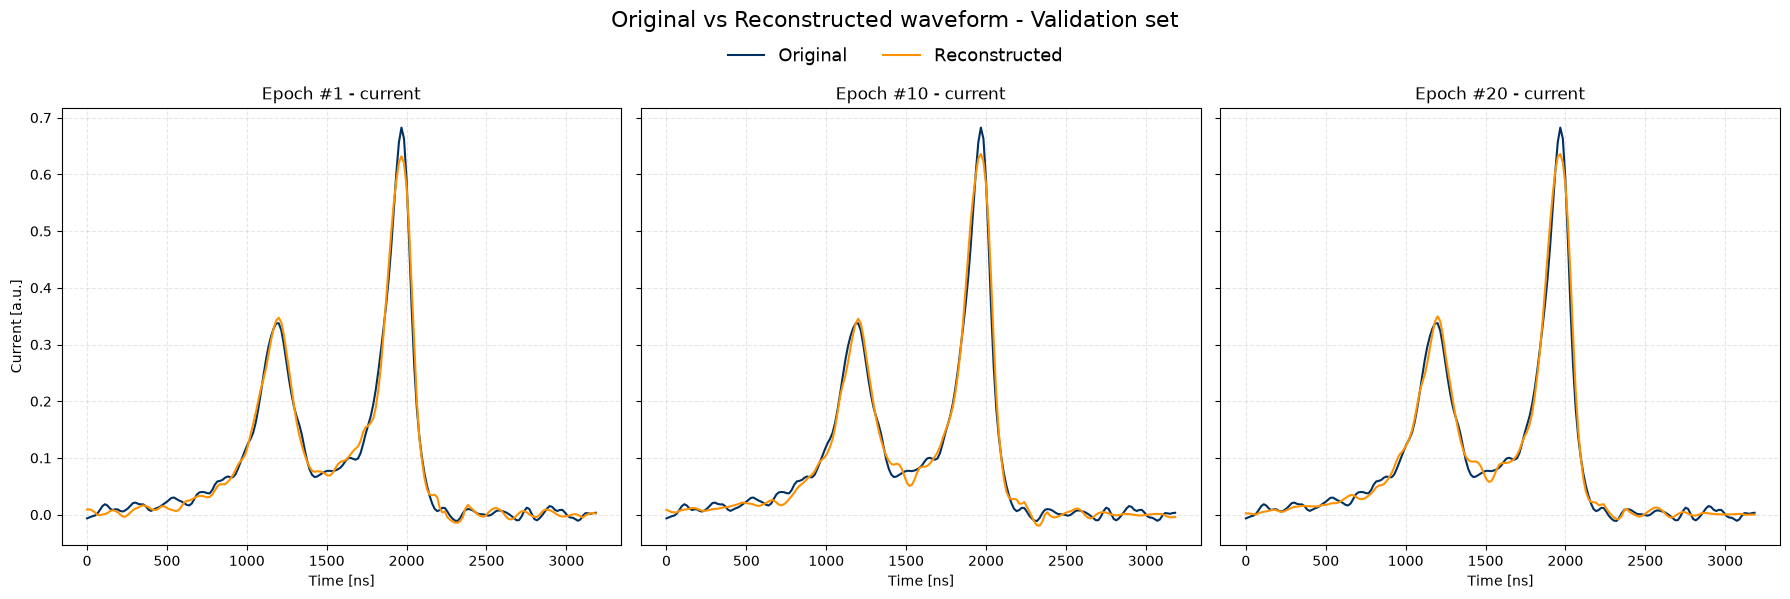

[euclidean, gamma=1000, 4 clusters] events that changed cluster with the training: 0.8887


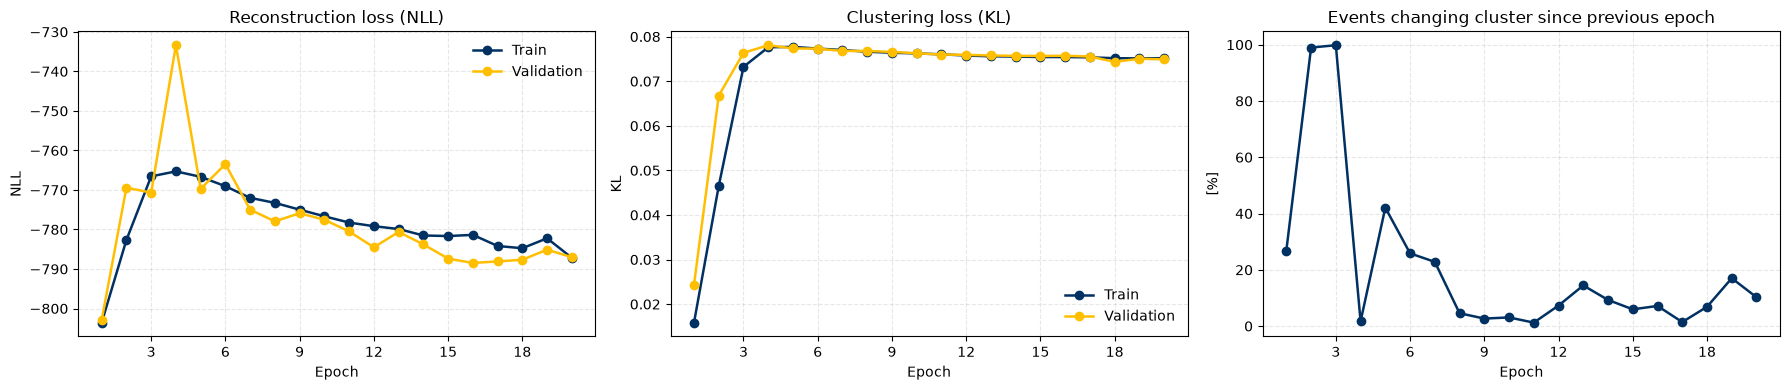

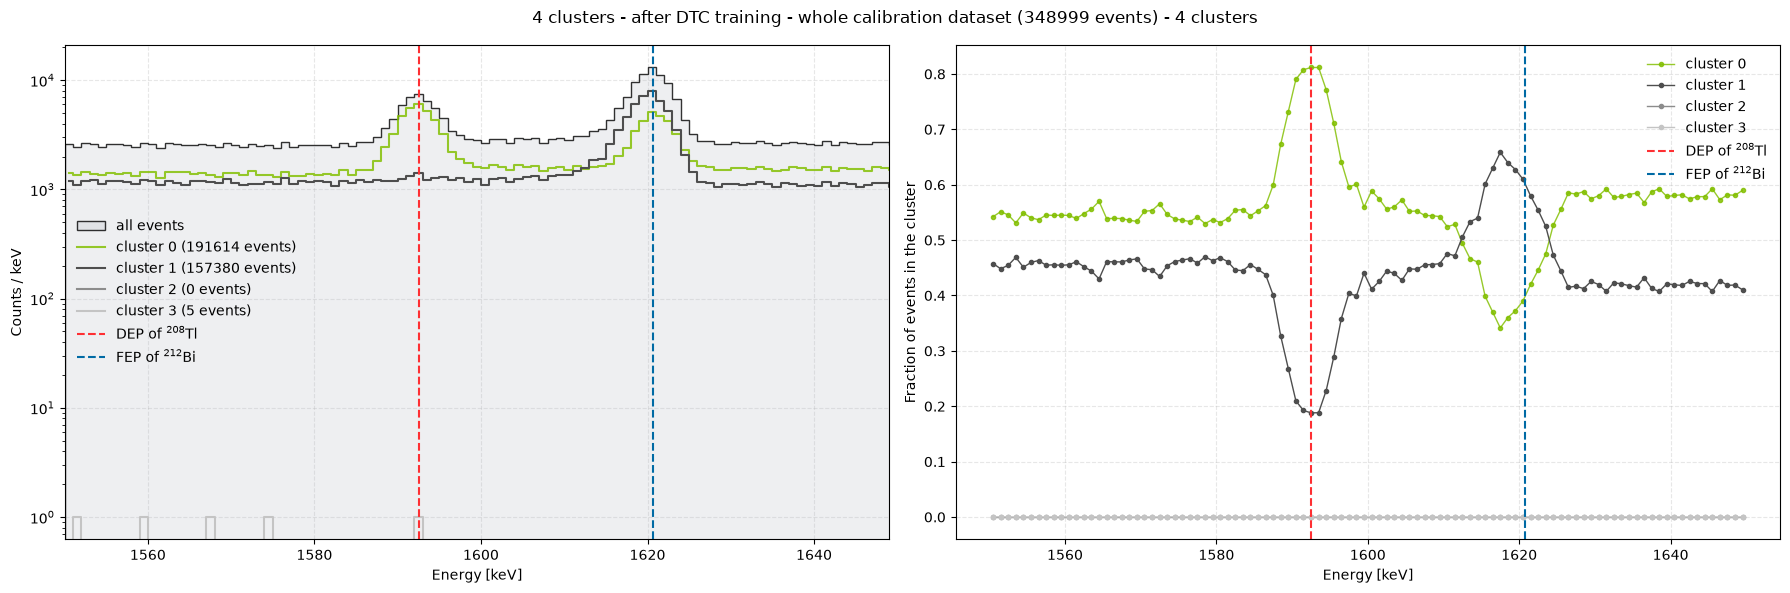

In [12]:
pf.TAG = SCAN_METRIC
scan_k = {}
for k in SCAN_CLUSTERS:
    if k == N_CLUSTERS and GAMMA in scan_gamma:
        scan_k[k] = scan_gamma[GAMMA]                       # same run: no need to train it again
    else:
        pf.PREFIX = f"scan_{SCAN_METRIC}_"                   # files scan_eucl_<K>cl_...
        scan_k[k] = cluster_run(k, METRICS[SCAN_METRIC], gamma=GAMMA, epochs=SCAN_EPOCHS)
    plot_energy_and_history(scan_k[k], f"scan_{SCAN_METRIC}_", label=f"{k} clusters")

In [13]:
loss_rows, comp_rows = [], []
for k, r in scan_k.items():
    h, y = r['model'].history, r['y']
    loss_rows.append({'clusters': k,
                      'NLL validation': h['nll_val'][-1],
                      'NLL change vs pretrain': h['nll_val'][-1] - pre_val_l[-1],
                      'KL validation': h['kl_val'][-1],
                      'moved from KMeans [%]': 100 * (r['y_init'] != y).mean(),
                      'changes last epoch [%]': 100 * h['changes'][-1]})
    size, dep_f, fep_f = composition(y, k)
    for j in range(k):
        comp_rows.append({'clusters / cluster': f"{k} / {j}", 'events [%]': 100 * size[j],
                          'DEP events in the cluster [%]': 100 * dep_f[j],
                          'FEP events in the cluster [%]': 100 * fep_f[j]})
save_table(pd.DataFrame(loss_rows).set_index('clusters'), f'table_scan_{SCAN_METRIC}_clusters_losses')
save_table(pd.DataFrame(comp_rows).set_index('clusters / cluster'), f'table_scan_{SCAN_METRIC}_clusters_composition')

,NLL validation,NLL change vs pretrain,KL validation,moved from KMeans [%],changes last epoch [%]
clusters,,,,,
2,-790.69,20.10,0.08,38.20,1.50
3,-790.45,20.34,0.08,93.56,1.85
4,-787.01,23.78,0.07,88.87,10.26


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_scan_eucl_clusters_losses.csv | table_scan_eucl_clusters_losses.tex


,events [%],DEP events in the cluster [%],FEP events in the cluster [%]
clusters / cluster,,,
2 / 0,50.06,70.36,35.44
2 / 1,49.94,29.64,64.56
3 / 0,0.00,0.00,0.00
3 / 1,50.44,30.06,65.03
3 / 2,49.56,69.94,34.97
4 / 0,54.90,73.31,41.94
4 / 1,45.09,26.69,58.06
4 / 2,0.00,0.00,0.00
4 / 3,0.00,0.00,0.00


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_scan_eucl_clusters_composition.csv | table_scan_eucl_clusters_composition.tex


events per cluster: {0: 191614, 1: 157380, 2: 0, 3: 5}
event 58444: E = 1567.27 keV | A/E = 107.488 | rise time = 128 ns | max current = 1.927
event 153225: E = 1559.81 keV | A/E = -20.729 | rise time = 560 ns | max current = 0.926
event 207391: E = 1574.98 keV | A/E = -5.404 | rise time = 384 ns | max current = 1.023
event 267417: E = 1592.28 keV | A/E = 63.626 | rise time = 144 ns | max current = 1.597
event 311248: E = 1551.14 keV | A/E = -13.852 | rise time = 944 ns | max current = 0.965


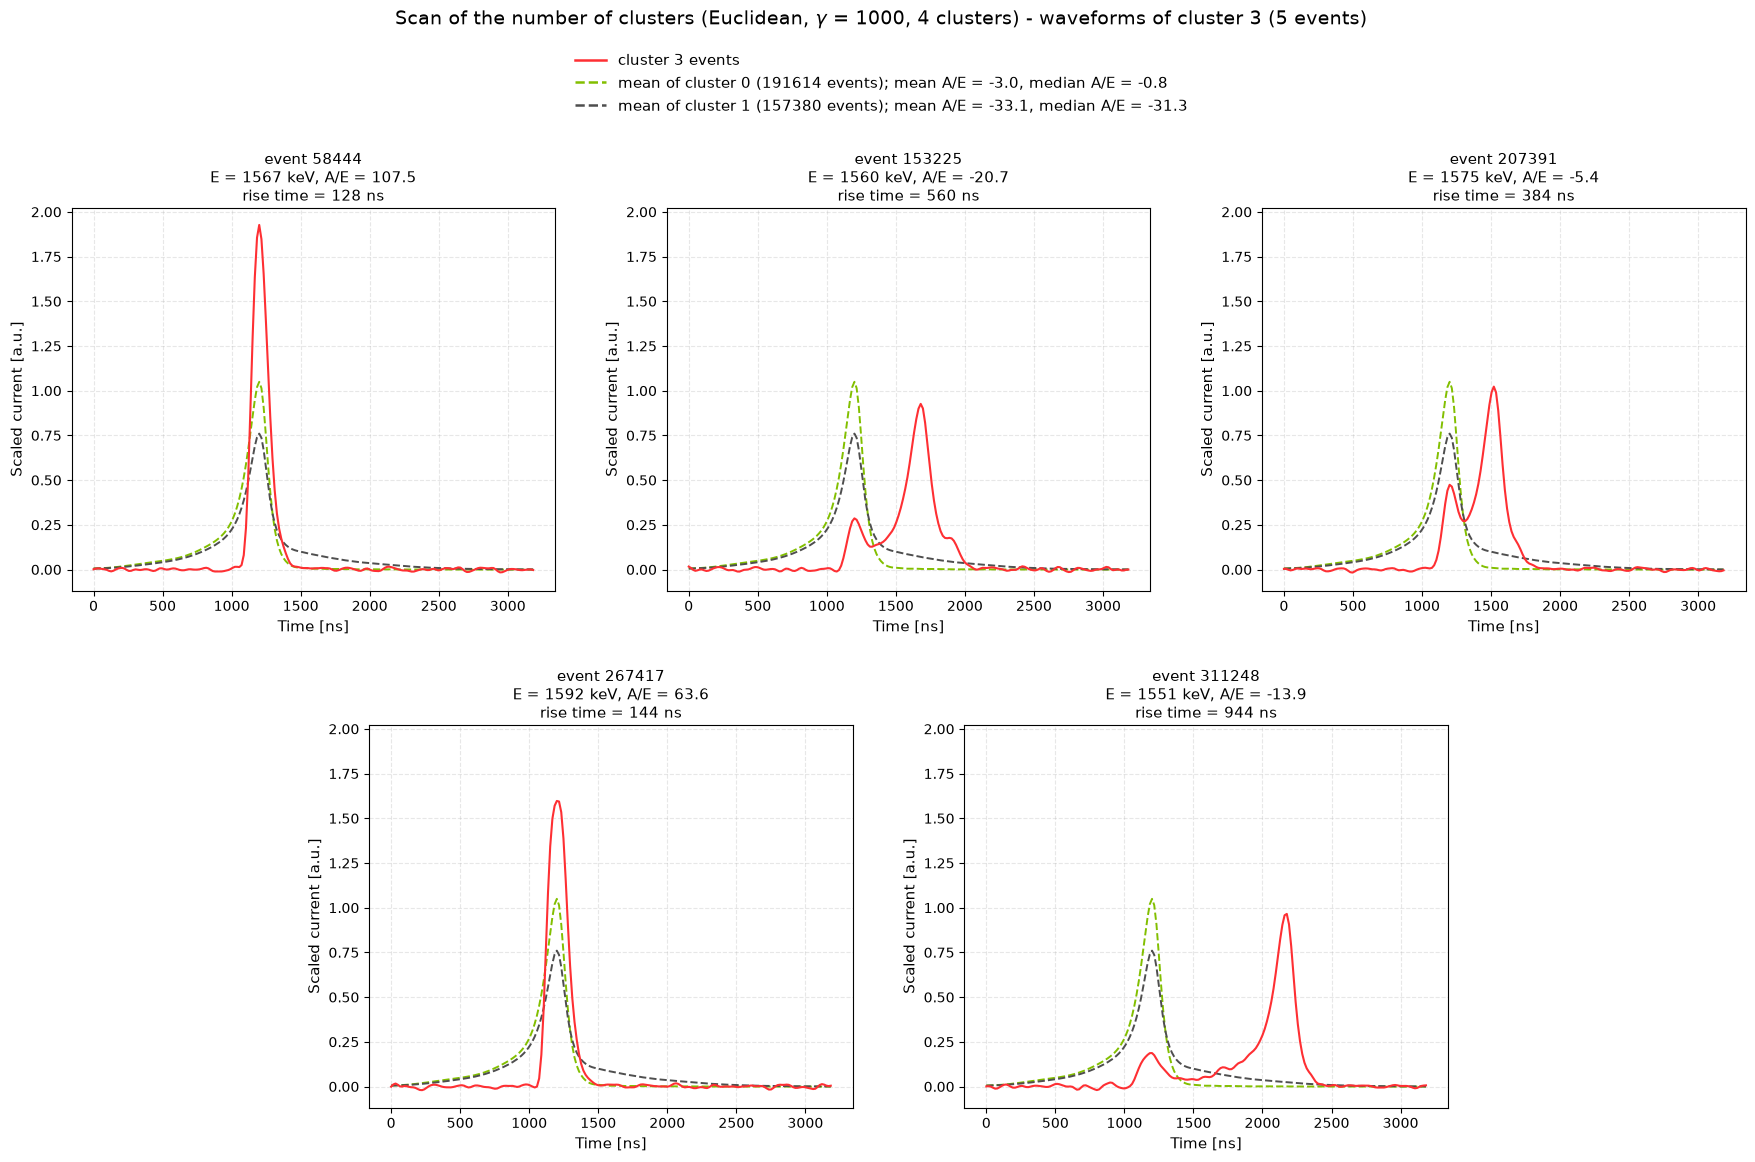

cluster 3: 5 events | mean A/E = 26.226


In [24]:
# ---- waveforms of cluster 3 (5 eventi): 3 sopra + 2 sotto, figura 18x12 ----
from matplotlib.lines import Line2D

K, CL = 4, 3
r  = scan_k[K]
yk = r['y']
print("events per cluster:", {j: int((yk == j).sum()) for j in range(K)})

idx = np.flatnonzero(yk == CL)                                      # i 5 eventi del cluster 3
cur = data['waves'][:, 0, :]
cur = cur.cpu().numpy() if hasattr(cur, 'cpu') else np.asarray(cur)
rt  = np.asarray(clean['rise_time_all'])[data['idx_sel']]
aoe = np.asarray(clean['AoE_all'])[data['idx_sel']]
t   = np.arange(cur.shape[1]) * 16                                  # ns

EVENT_COLOR = '#fe2f33'
MEAN_COLORS = {0: '#82bf00', 1: '#4e4e4e', 2: '#013162', 3: '#013162'}

# mean waveforms dei cluster popolati (disegnate in ogni pannello)
means = []
for j in range(K):
    m = yk == j
    if j != CL and m.sum() > 100:
        means.append((j, cur[m].mean(axis=0),
                      f"mean of cluster {j} ({m.sum()} events); "
                      f"mean A/E = {np.nanmean(aoe[m]):.1f}, median A/E = {np.nanmedian(aoe[m]):.1f}"))

n_ev = len(idx)                                                     # 5

# griglia 2x6: i primi 3 eventi occupano le colonne 0-1, 2-3, 4-5 della riga alta,
# gli altri 2 sono centrati nella riga bassa (colonne 1-2 e 3-4)
fig = plt.figure(figsize=(18, 12))
gs  = fig.add_gridspec(2, 6, hspace=0.35, wspace=0.6)
slots = [gs[0, 0:2], gs[0, 2:4], gs[0, 4:6], gs[1, 1:3], gs[1, 3:5]]

axs = []
for n, i in enumerate(idx[:5]):
    ax = fig.add_subplot(slots[n], sharey=axs[0] if axs else None)
    axs.append(ax)

    for j, mean_wf, lab in means:
        ax.plot(t, mean_wf, ls='--', lw=1.4, color=MEAN_COLORS[j])
    ax.plot(t, cur[i], lw=1.5, color=EVENT_COLOR)
    print(f"event {i}: E = {energy[i]:.2f} keV | A/E = {aoe[i]:.3f} | "
          f"rise time = {rt[i]:.0f} ns | max current = {cur[i].max():.3f}")

    ax.set_title(f"event {i}\nE = {energy[i]:.0f} keV, A/E = {aoe[i]:.1f}\nrise time = {rt[i]:.0f} ns",
                 fontsize=11, pad=5)
    ax.tick_params(labelsize=10)
    ax.grid(alpha=0.3, ls='--'); ax.set_axisbelow(True)
    ax.set_xlabel("Time [ns]", fontsize=11)
    ax.set_ylabel("Scaled current [a.u.]", fontsize=11)

handles = [Line2D([0], [0], color=EVENT_COLOR, lw=1.8, label=f"cluster {CL} events")]
handles += [Line2D([0], [0], color=MEAN_COLORS[j], lw=1.8, ls='--', label=lab) for j, _, lab in means]

fig.suptitle(f"Scan of the number of clusters ({NAMES[SCAN_METRIC]}, $\\gamma$ = {GAMMA}, {K} clusters) - "
             f"waveforms of cluster {CL} ({n_ev} events)", fontsize=14, y=0.985)
fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.96),
           ncol=1, frameon=False, fontsize=11)
fig.subplots_adjust(top=0.82, bottom=0.07, left=0.05, right=0.98)

plt.savefig(os.path.join(pf.PLOT_DIR, f"scan_{SCAN_METRIC}_{K}cl_cluster{CL}_waveforms.pdf"), dpi=300)
plt.show()

if n_ev:
    print(f"cluster {CL}: {n_ev} events | mean A/E = {np.nanmean(aoe[idx]):.3f}")

# 3. FINAL RUNS: ACF, EUCLIDEAN, CID
2 clusters, $\gamma$ = 1000, `TRAINING_EPOCHS` epochs. For every metric (files `<metric>_...`):
- reconstruction after the training (made inside `DTC.training`) and training history;
- table of the losses of every epoch;
- clusters vs energy and A/E + rise time on the **training**, **validation** and **test** set;
- weights and bundle saved in `finalmodels/` (format read by DTC-allMETRICS and by the 2$\nu\beta\beta$ analysis).

In [15]:
def run_final(tag):
    
    metric = METRICS[tag]
    pf.TAG, pf.PREFIX = tag, f"{tag}_"
    run = cluster_run(N_CLUSTERS, metric, gamma=GAMMA, epochs=TRAINING_EPOCHS)
    y = run['y']
    colors = pf.cluster_colors(y, energy, N_CLUSTERS)       # from ALL the events: same colors in every plot
    
    pf.plot_training_history(run['model'].history, name=f"{N_CLUSTERS}cl_training_history")
    for split in ('train', 'val', 'test'):
        idx = data[f'idx_{split}']
        title = pf._title(N_CLUSTERS, split, len(idx))
        pf.plot_clusters_vs_energy(y[idx], energy[idx], N_CLUSTERS, title=title,
                                   name=f"{N_CLUSTERS}cl_energy_{split}", colors=colors)
        pf.plot_cluster_variables(y[idx], data['AoE'][idx], data['rise_time'][idx], N_CLUSTERS, title=title,
                                  name=f"{N_CLUSTERS}cl_AoE_risetime_{split}", colors=colors)
    
    save_table(training_table(run), f'table_{tag}_training_losses')
    
    # SSE-like cluster and saving (same formats as before)
    run['sse_cluster'] = s = sse_like(y, N_CLUSTERS)
    _, dep_f, fep_f = composition(y, N_CLUSTERS)
    print(f"{metric}: DEP per cluster {np.round(dep_f, 3)} | FEP per cluster {np.round(fep_f, 3)} -> SSE-like cluster = {s}")
    
    base = os.path.join(OUT_DIR, f"dtc{N_CLUSTERS}_{metric}_gamma{GAMMA}_{TRAINING_EPOCHS}ep")
    model = run['model']
    torch.save({'state_dict': model.state_dict(), 'sse_cluster': s}, base + ".pth")
    bundle = dict(
        state_dict=model.state_dict(),
        model_kwargs=dict(input_length=int(data['waves'].shape[-1]), pool_size=10, n_clusters=N_CLUSTERS,
                          distance_metric=metric, use_charge=use_charge),
        config={k: (v.item() if hasattr(v, 'item') else v) for k, v in data['config'].items()},
        scale_factor=float(data['scale_factor']),
        charge_scale_factor=float(data['charge_scale_factor']),
        channels=int(data['channels']),
        wfcleaning_file=os.path.abspath(preliminary.wfcleaning.__file__),
        cleaning_kwargs=dict(baseline_points=300, n_sigmas=3, pre_trigger_points=75, post_trigger_points=124),
        dep_frac=dep_f, fep_frac=fep_f, sse_cluster=s,
        gamma=GAMMA, epochs=TRAINING_EPOCHS, pretraining_epochs=PRETRAINING_EPOCHS, tae_file=os.path.abspath(TAE_PATH),
    )
    torch.save(bundle, base + "_bundle.pth")
    print("saved:", os.path.abspath(base + ".pth"), "|", os.path.abspath(base + "_bundle.pth"))
    return run


runs = {}

#### ACF

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans
Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.911 0.089]
[train] epoch 1/100 - train: -802.4637  val: -800.8888  events per cluster: [0.043 0.957]  changes: 0.8686
        NLL: -806.73   KL: 0.0043
[train] epoch 2/100 - train: -799.7489  val: -787.2368  events per cluster: [0.558 0.442]  changes: 0.5146
        NLL: -807.72   KL: 0.0080
[train] epoch 3/100 - train: -736.3555  val: -681.0635  events per cluster: [0.545 0.455]  changes: 0.0826
        NLL: -779.60   KL: 0.0432
[train] epoch 4/100 - train: -690.3353  val: -687.7969  events per cluster: [0.512 0.488]  changes: 0.0347
        NLL: -762.43   KL: 0.0721
[train] epoch 5/100 - train: -686.1464  val: -686.5156  events per cluster: [0.511 0.489]  changes: 0.0087
        NLL: -762.98   KL: 0.0768
[train] epoch 6/100 - train: -686.7295  val: -689.9620  events per cluster: [0.488 0.512]  changes: 0.0230

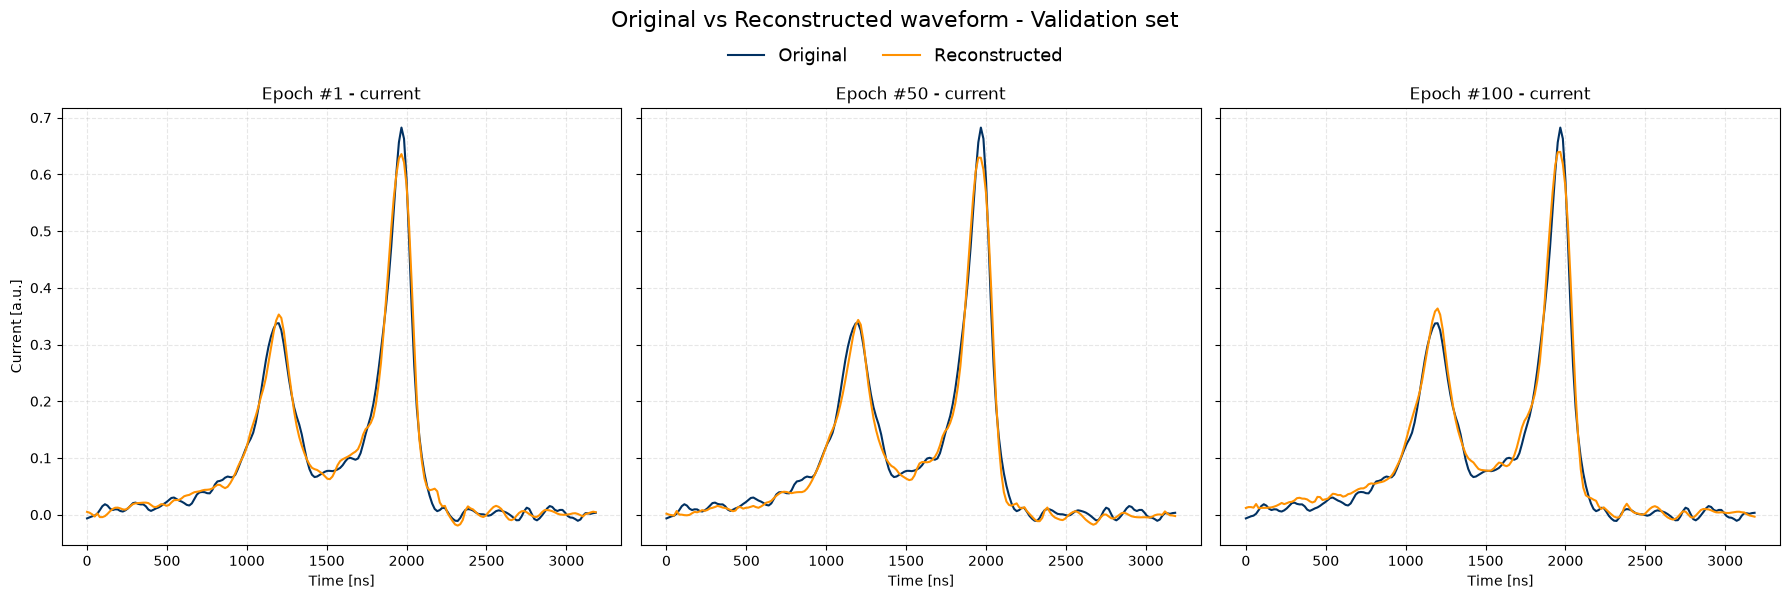

[acf, gamma=1000, 2 clusters] events that changed cluster with the training: 0.4819


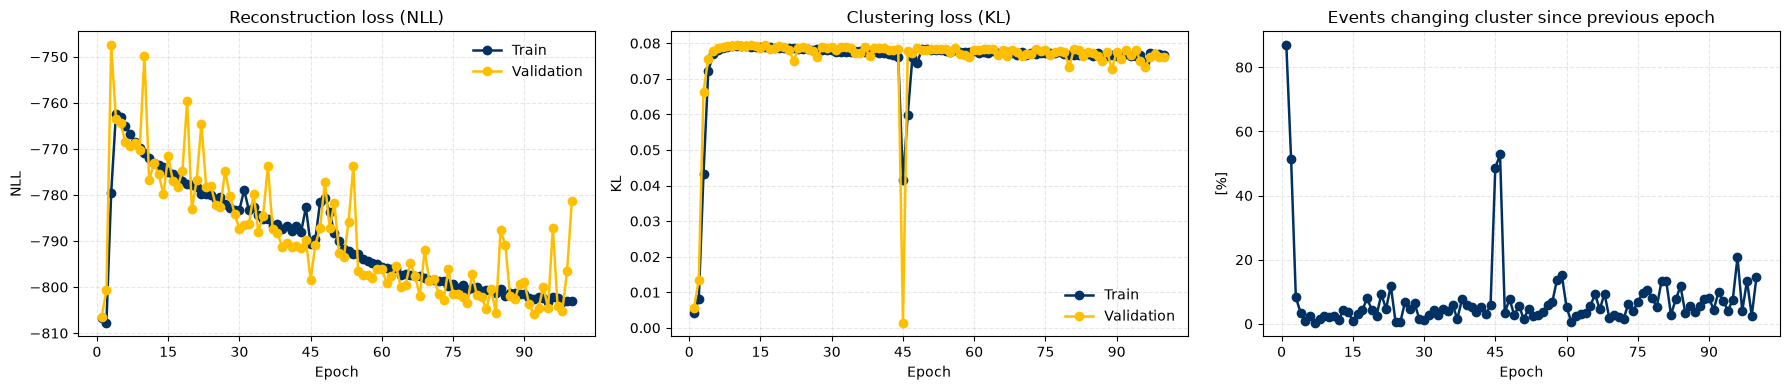

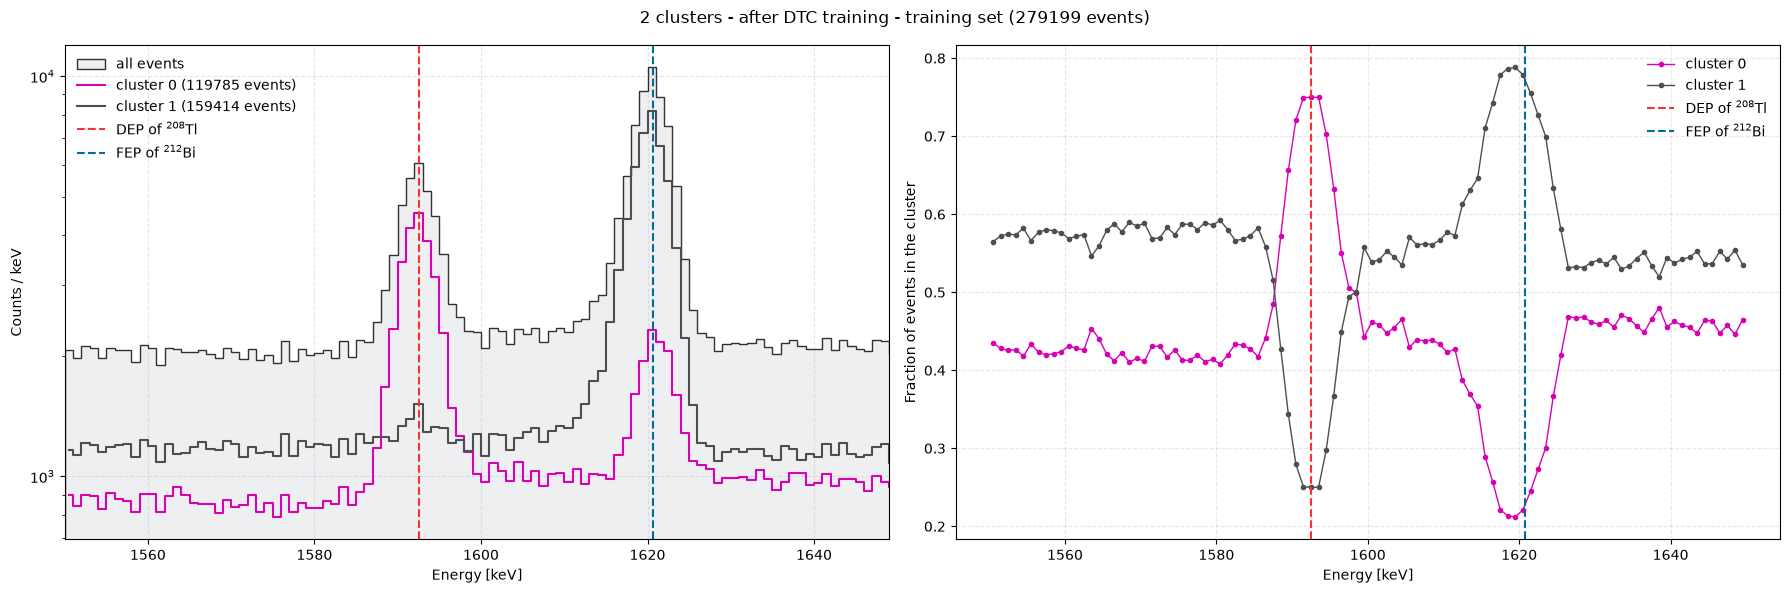

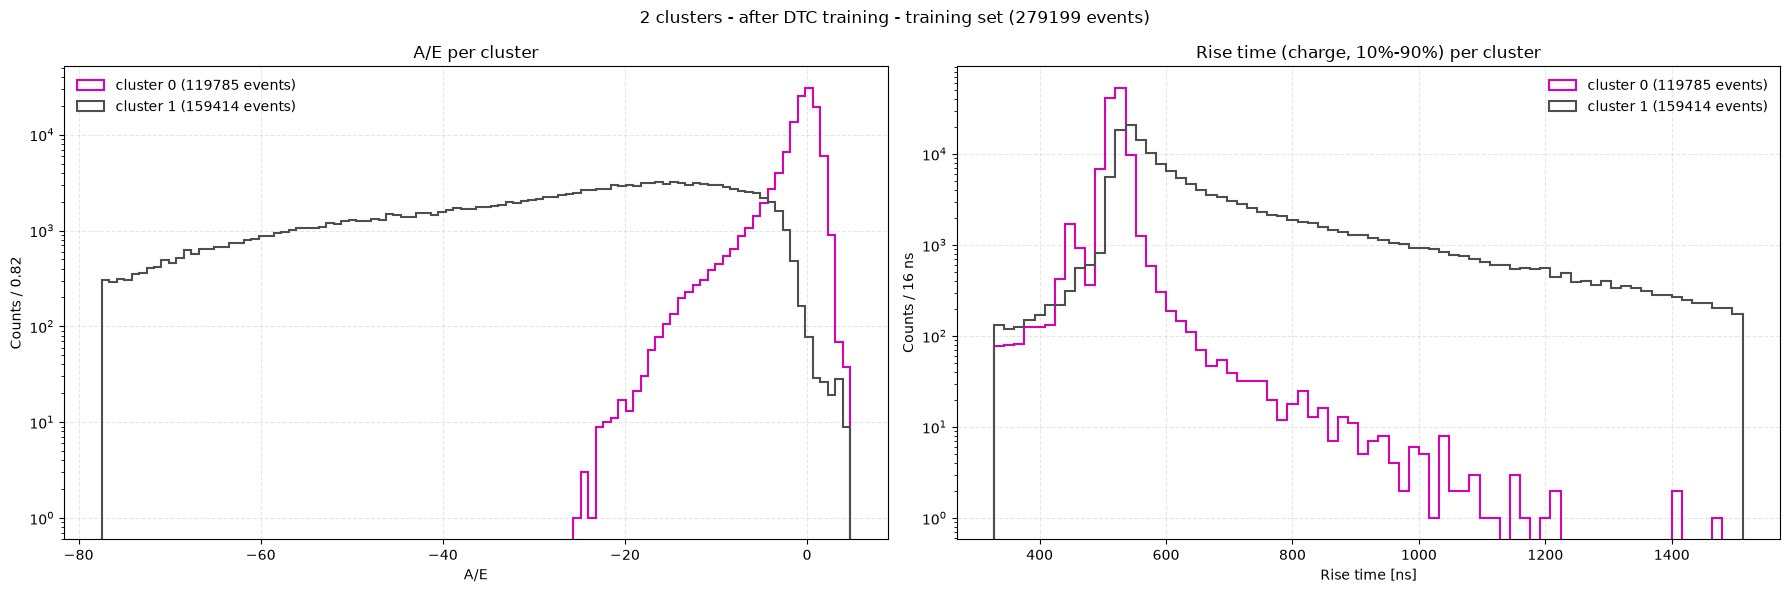

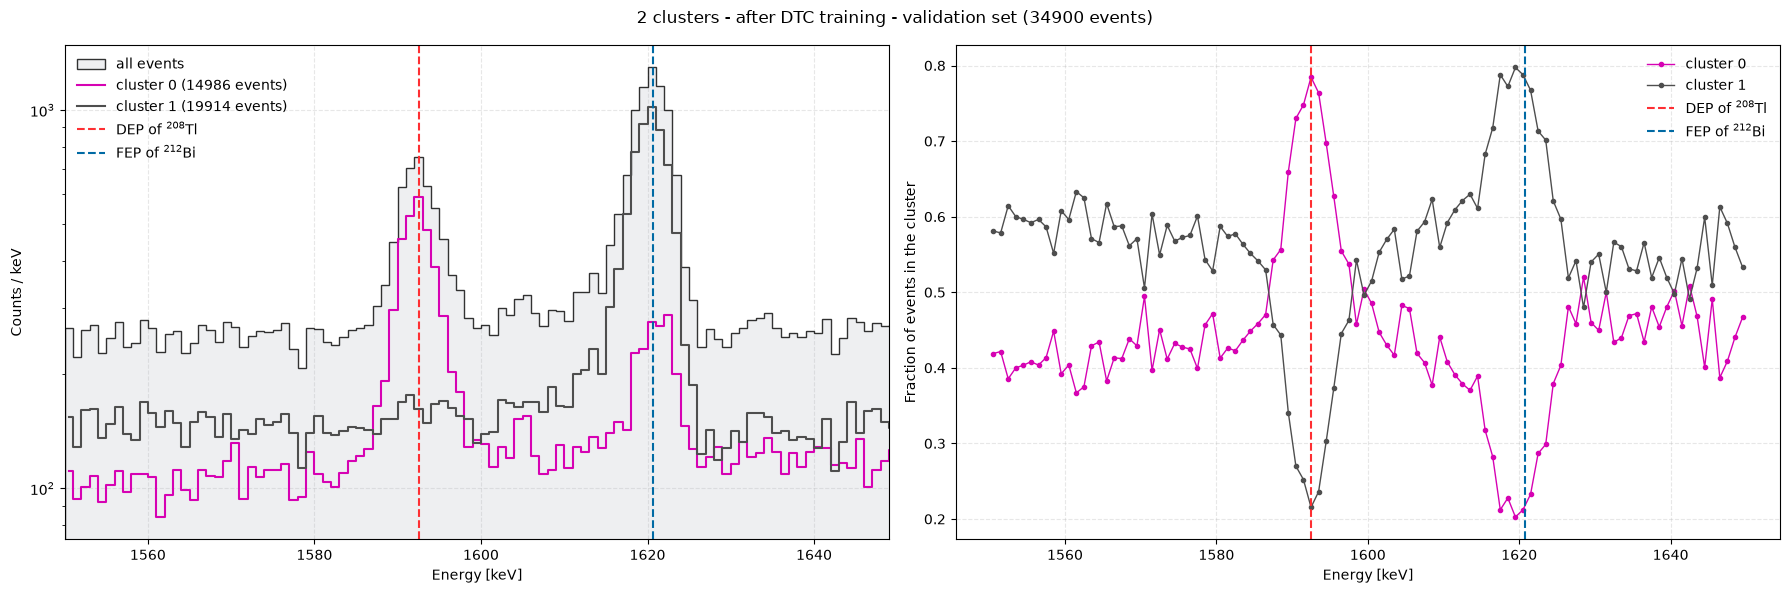

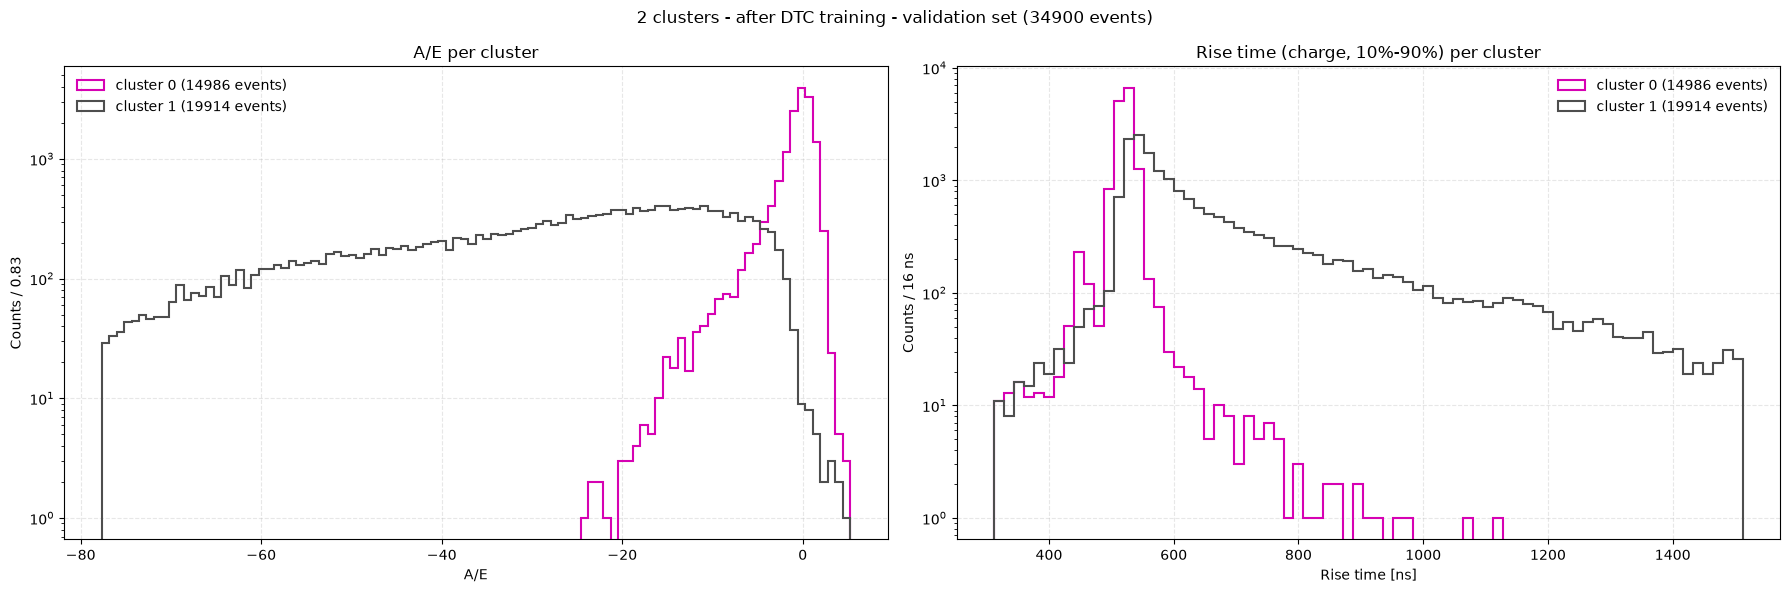

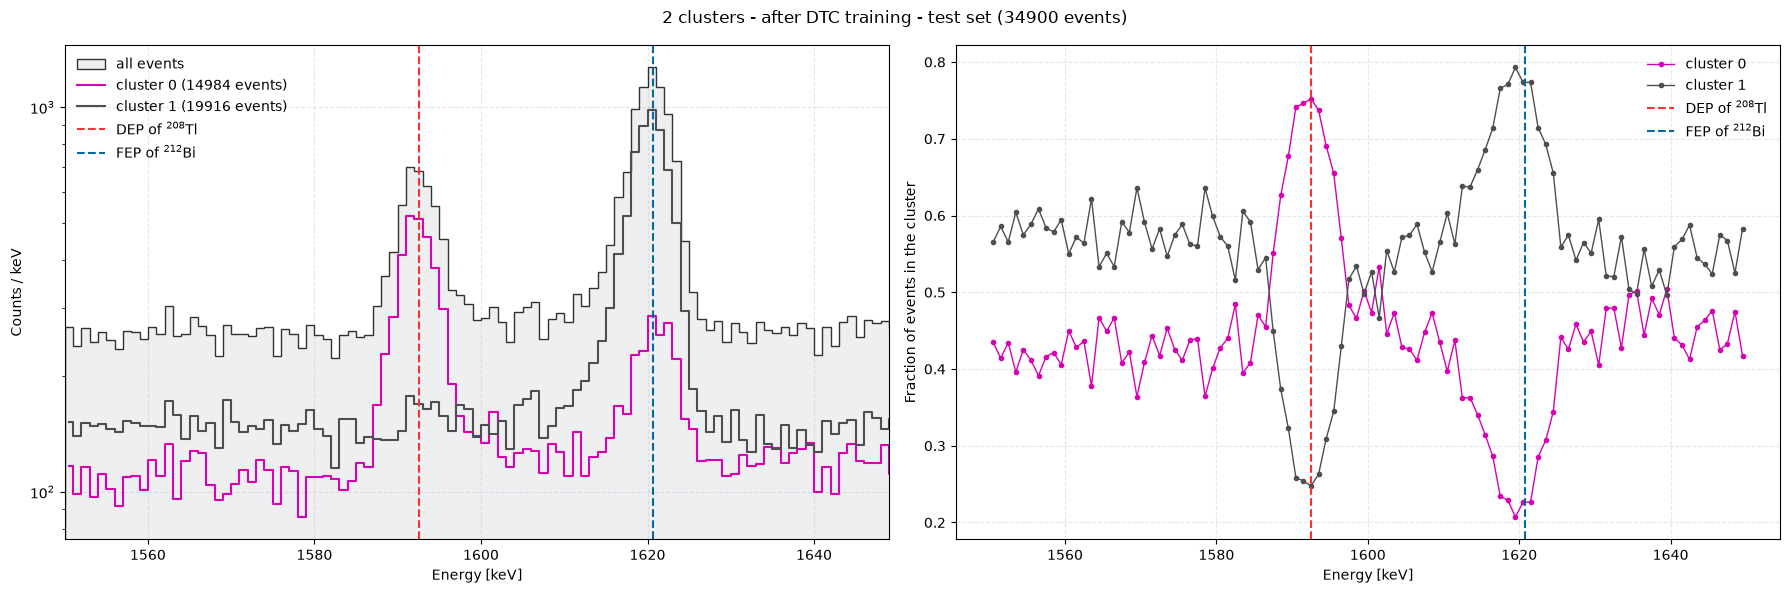

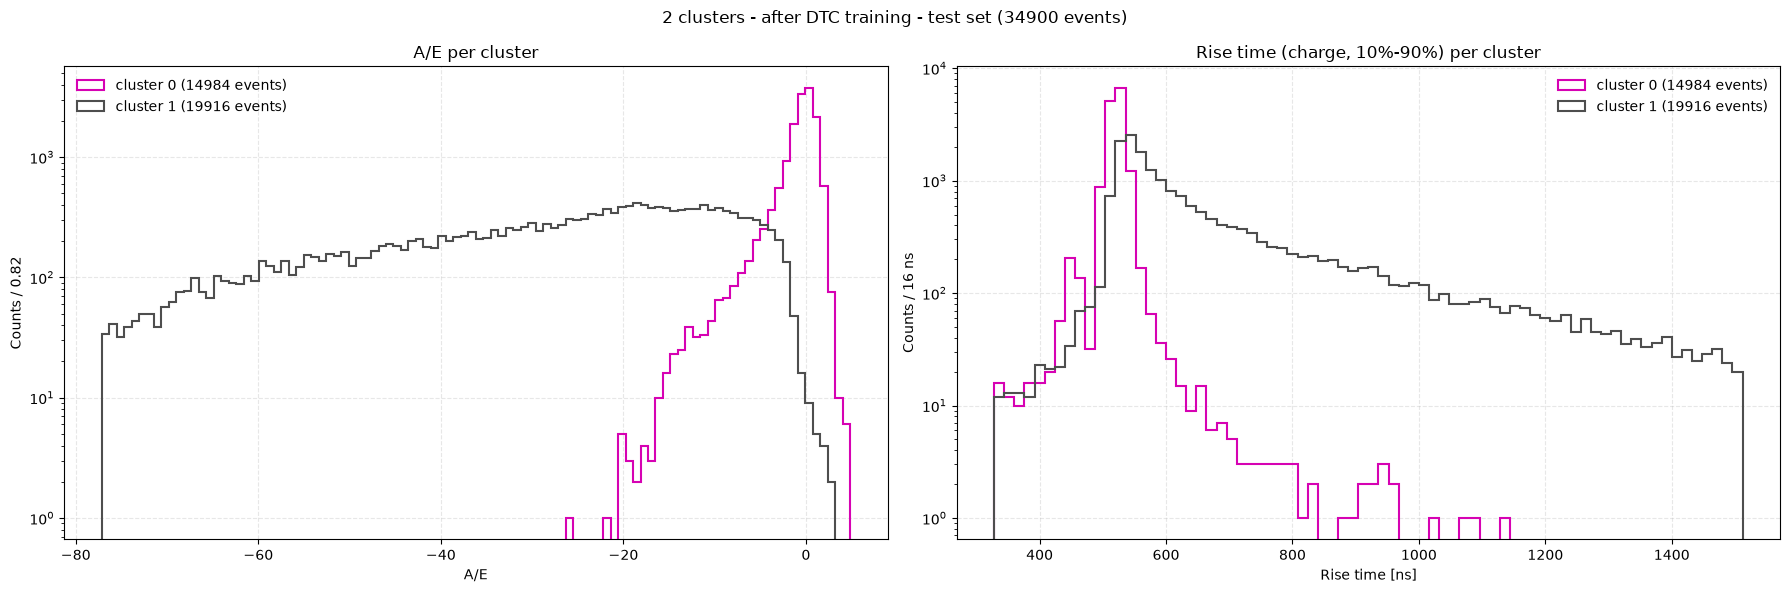

,total train,total validation,NLL train,NLL validation,KL train,KL validation,changes [%],events per cluster
epoch,,,,,,,,
1,-802.46,-800.89,-806.73,-806.41,0.00,0.01,86.86,0.04/0.96
2,-799.75,-787.24,-807.72,-800.71,0.01,0.01,51.46,0.56/0.44
3,-736.36,-681.06,-779.60,-747.49,0.04,0.07,8.26,0.55/0.45
4,-690.34,-687.80,-762.43,-763.43,0.07,0.08,3.47,0.51/0.49
5,-686.15,-686.52,-762.98,-764.36,0.08,0.08,0.87,0.51/0.49
...,...,...,...,...,...,...,...,...
96,-727.55,-713.68,-802.21,-787.07,0.07,0.07,20.77,0.39/0.61
97,-725.16,-727.98,-802.36,-804.12,0.08,0.08,3.97,0.43/0.57
98,-726.41,-728.28,-803.33,-805.13,0.08,0.08,13.48,0.56/0.44


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_acf_training_losses.csv | table_acf_training_losses.tex
acf: DEP per cluster [0.658 0.342] | FEP per cluster [0.27 0.73] -> SSE-like cluster = 0
saved: /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/dtc2_acf_gamma1000_100ep.pth | /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/dtc2_acf_gamma1000_100ep_bundle.pth


In [16]:
runs['acf'] = run_final('acf')

#### Euclidean

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans


Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.118 0.882]
[train] epoch 1/100 - train: -787.6920  val: -778.3406  events per cluster: [0.122 0.878]  changes: 0.0067
        NLL: -803.53   KL: 0.0158
[train] epoch 2/100 - train: -735.8548  val: -706.7694  events per cluster: [0.462 0.538]  changes: 0.3404
        NLL: -782.58   KL: 0.0467
[train] epoch 3/100 - train: -693.5741  val: -689.8112  events per cluster: [0.496 0.504]  changes: 0.0340
        NLL: -766.85   KL: 0.0733
[train] epoch 4/100 - train: -688.3874  val: -681.7475  events per cluster: [0.511 0.489]  changes: 0.0152
        NLL: -766.02   KL: 0.0776
[train] epoch 5/100 - train: -689.0987  val: -693.6322  events per cluster: [0.551 0.449]  changes: 0.0400
        NLL: -766.79   KL: 0.0777
[train] epoch 6/100 - train: -691.6747  val: -696.8392  events per cluster: [0.484 0.516]  changes: 0.0673
        NLL: -769.06   KL: 0.0774
[train] epoch 7/100 - train: -694.8329  val: 

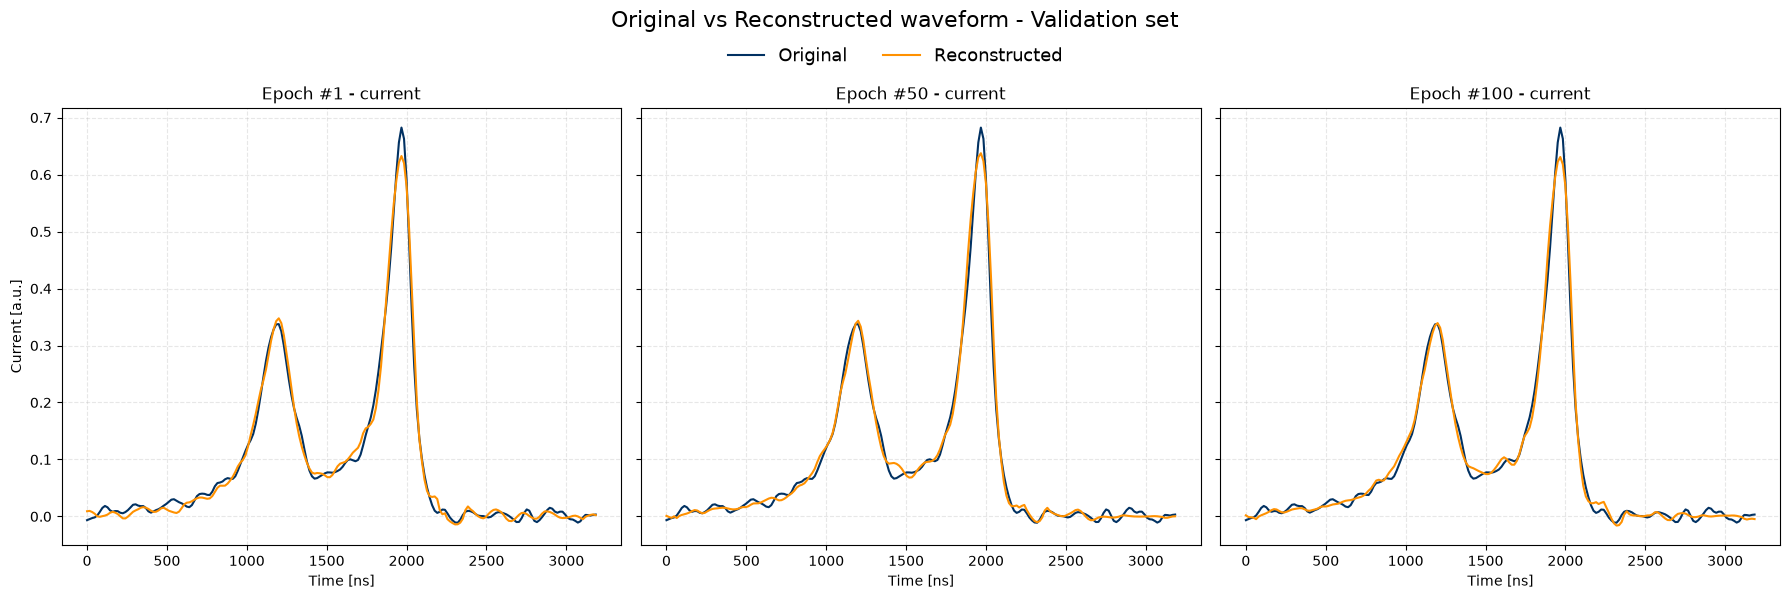

[euclidean, gamma=1000, 2 clusters] events that changed cluster with the training: 0.4558


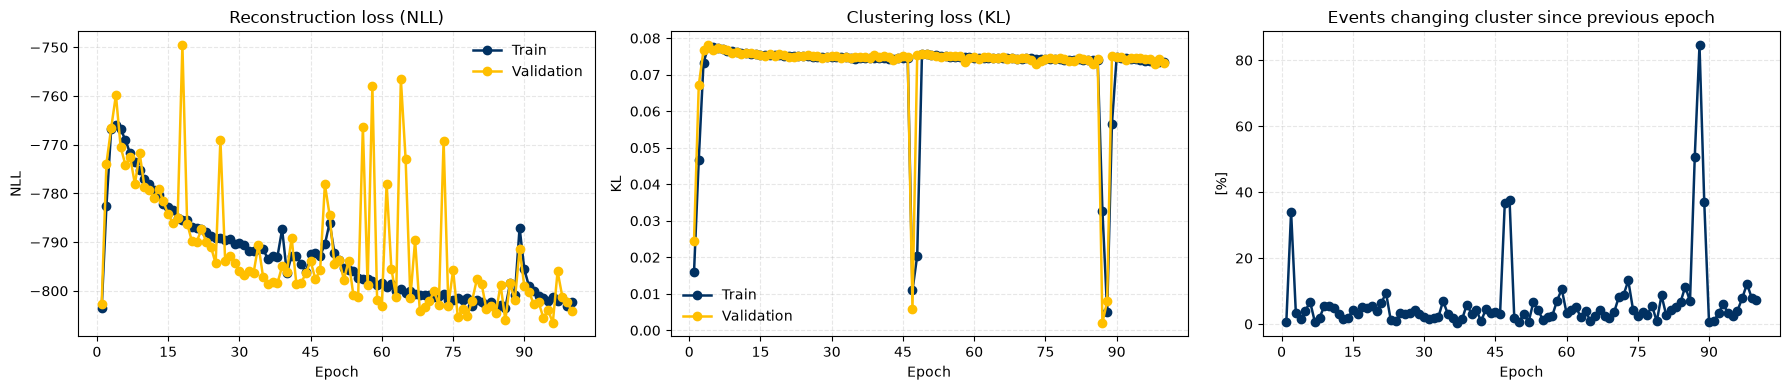

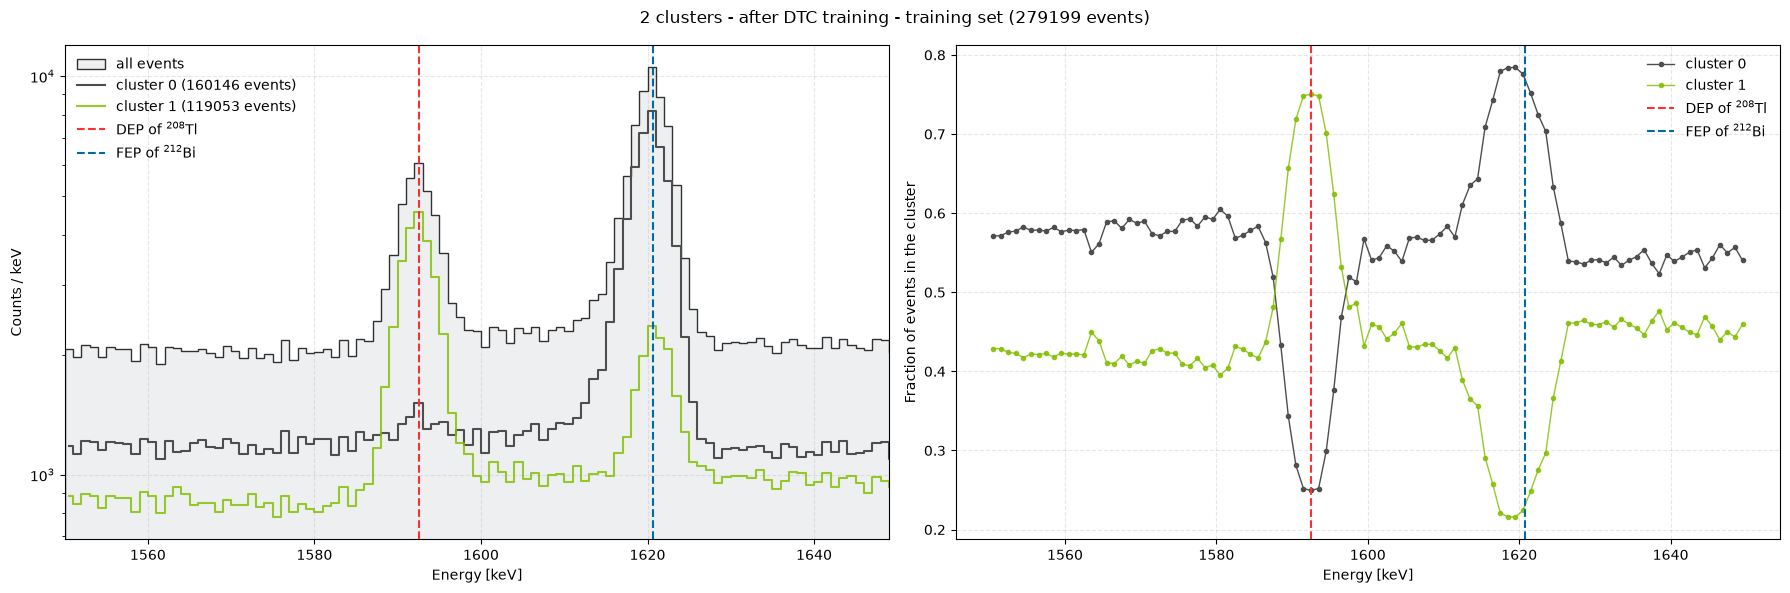

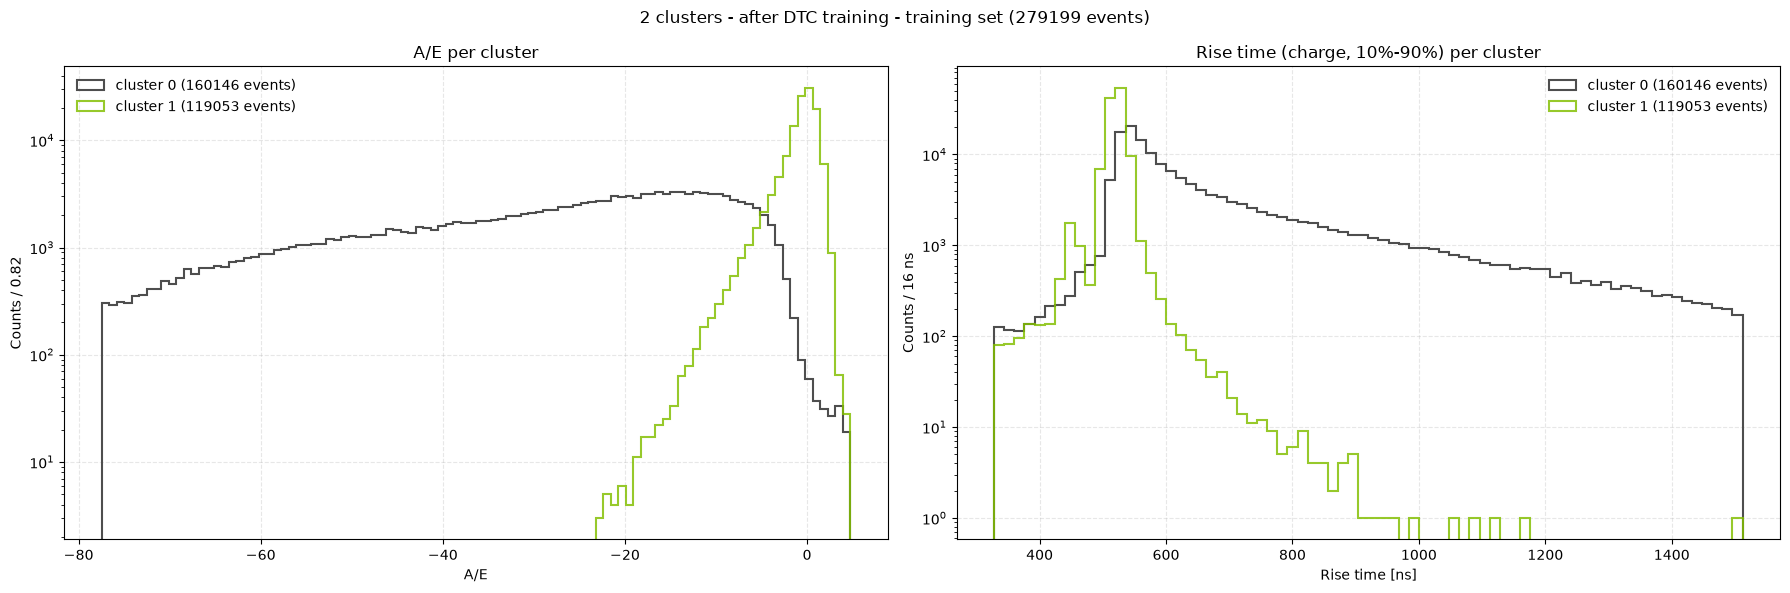

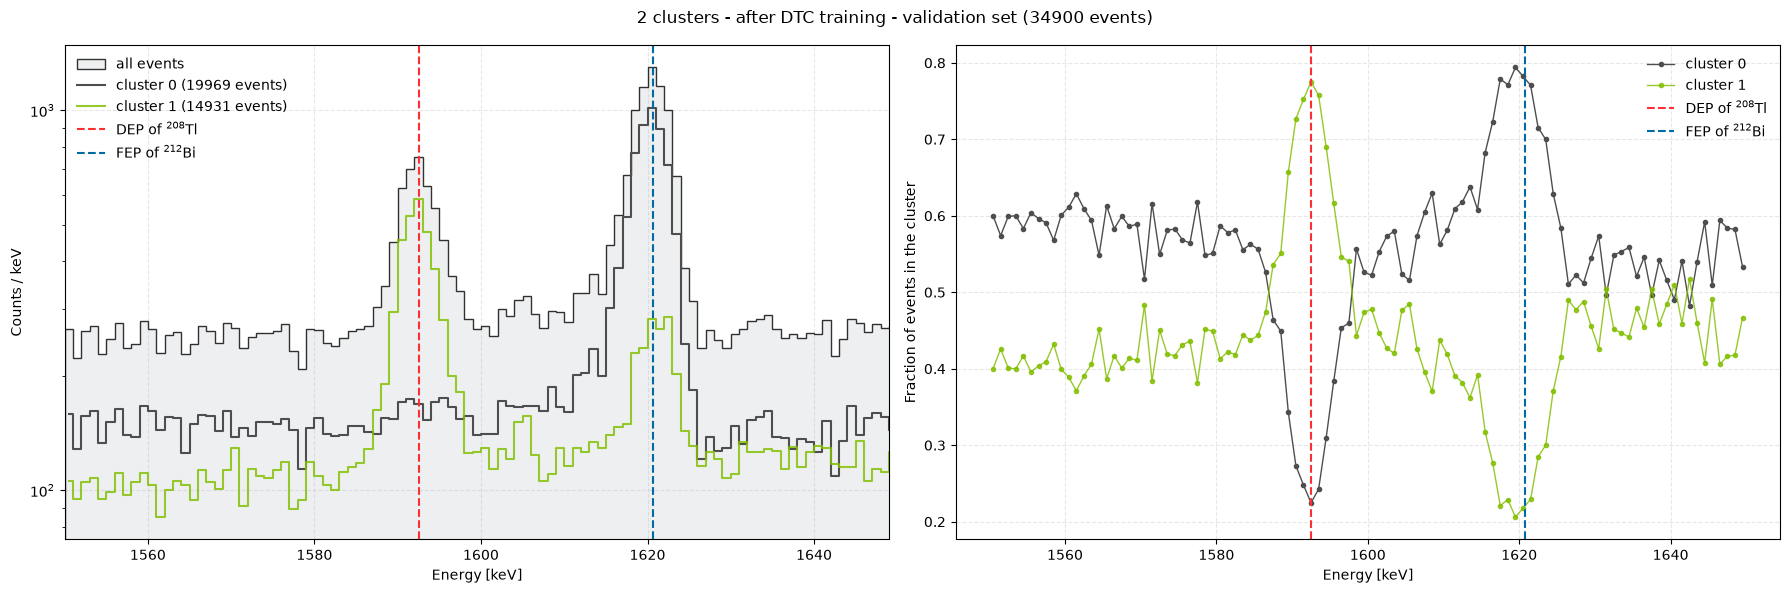

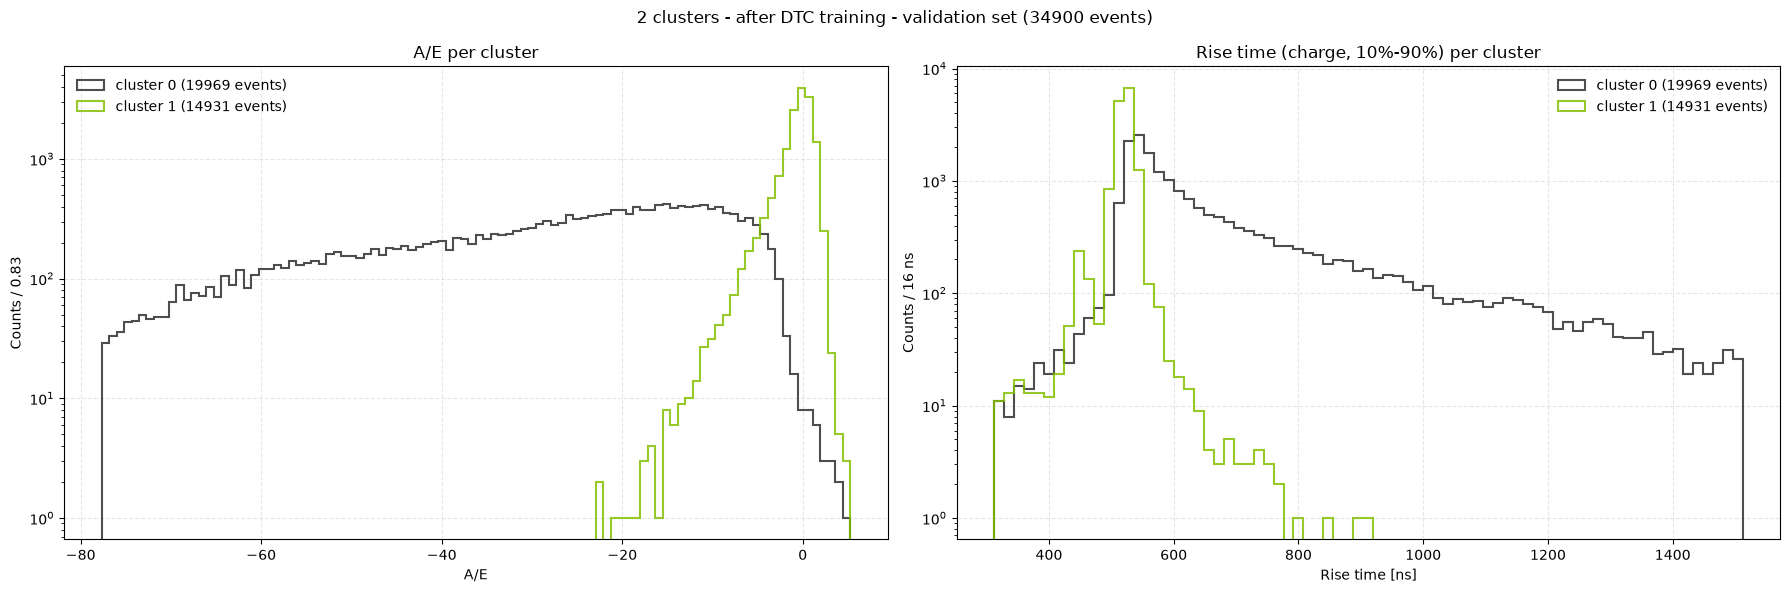

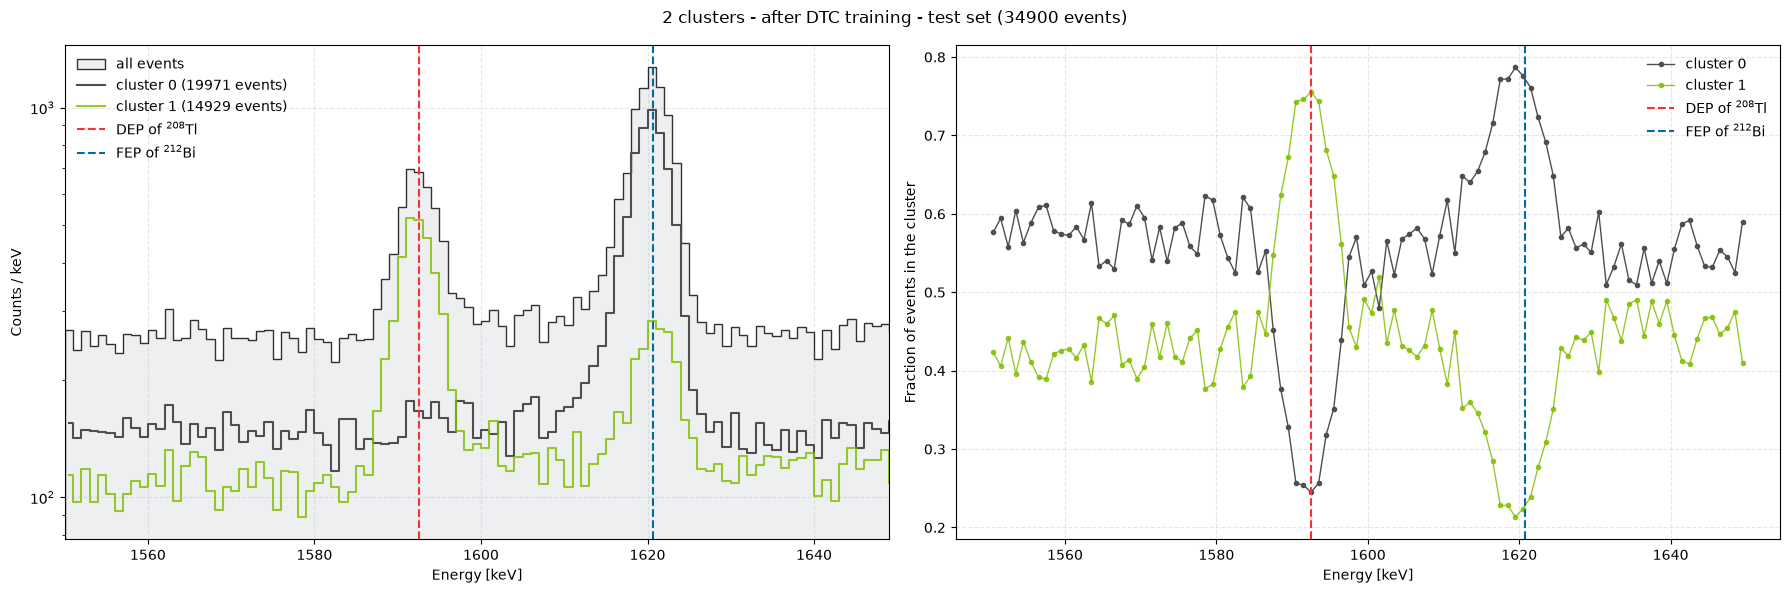

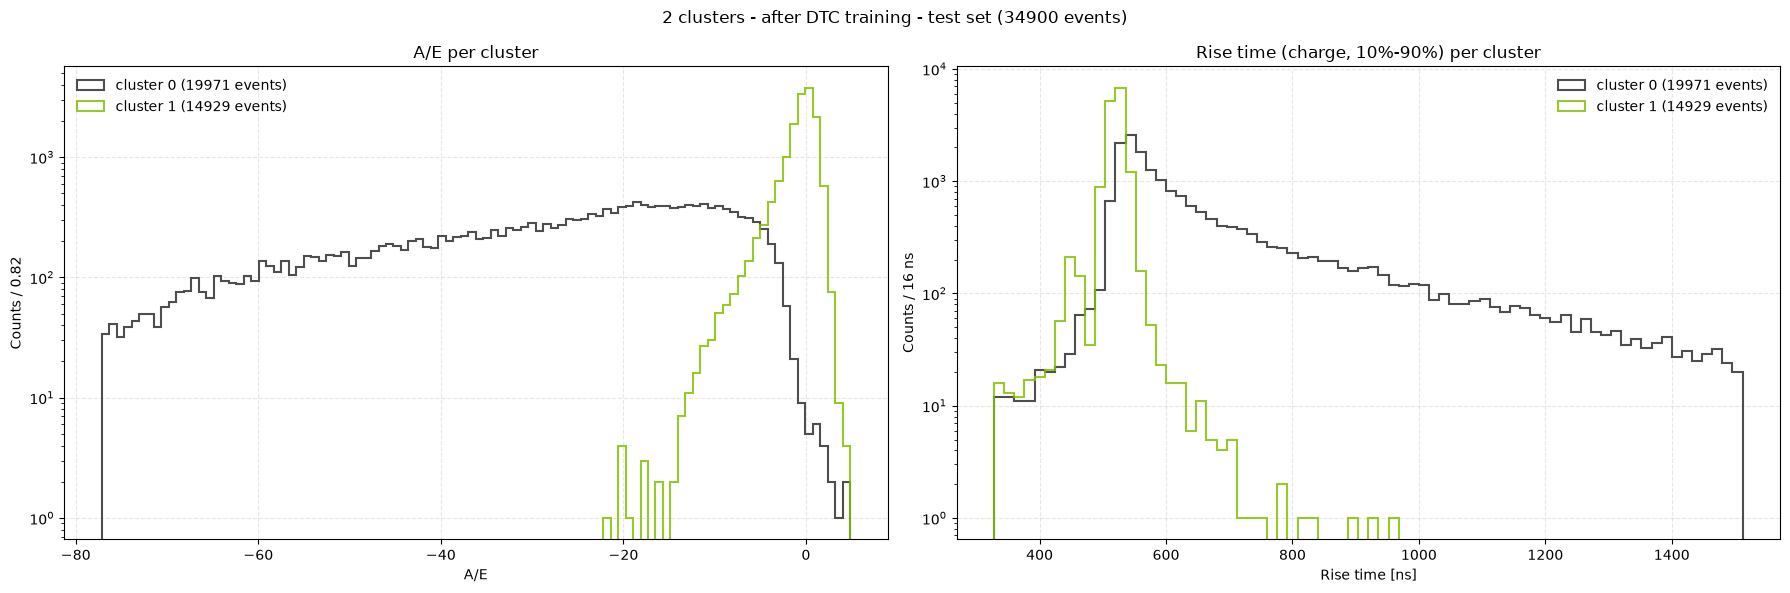

,total train,total validation,NLL train,NLL validation,KL train,KL validation,changes [%],events per cluster
epoch,,,,,,,,
1,-787.69,-778.34,-803.53,-802.78,0.02,0.02,0.67,0.12/0.88
2,-735.85,-706.77,-782.58,-773.86,0.05,0.07,34.04,0.46/0.54
3,-693.57,-689.81,-766.85,-766.55,0.07,0.08,3.40,0.50/0.50
4,-688.39,-681.75,-766.02,-759.82,0.08,0.08,1.52,0.51/0.49
5,-689.10,-693.63,-766.79,-770.47,0.08,0.08,4.00,0.55/0.45
...,...,...,...,...,...,...,...,...
96,-727.60,-732.21,-801.33,-806.52,0.07,0.07,4.08,0.54/0.46
97,-728.51,-721.79,-802.15,-796.01,0.07,0.07,7.83,0.46/0.54
98,-728.01,-728.28,-801.47,-801.19,0.07,0.07,12.18,0.58/0.42


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_eucl_training_losses.csv | table_eucl_training_losses.tex
euclidean: DEP per cluster [0.347 0.653] | FEP per cluster [0.729 0.271] -> SSE-like cluster = 1
saved: /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/dtc2_euclidean_gamma1000_100ep.pth | /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/dtc2_euclidean_gamma1000_100ep_bundle.pth


In [17]:
runs['eucl'] = run_final('eucl')

#### CID

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans
Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.905 0.095]
[train] epoch 1/100 - train: -726.8983  val: -737.0981  events per cluster: [0.488 0.512]  changes: 0.4172
        NLL: -766.81   KL: 0.0399
[train] epoch 2/100 - train: -742.3251  val: -751.1352  events per cluster: [0.475 0.525]  changes: 0.0134
        NLL: -767.49   KL: 0.0252
[train] epoch 3/100 - train: -751.9151  val: -753.1161  events per cluster: [0.492 0.508]  changes: 0.0178
        NLL: -772.70   KL: 0.0208
[train] epoch 4/100 - train: -757.6411  val: -765.2005  events per cluster: [0.498 0.502]  changes: 0.0085
        NLL: -775.87   KL: 0.0182
[train] epoch 5/100 - train: -762.2128  val: -765.9611  events per cluster: [0.519 0.481]  changes: 0.0212
        NLL: -778.84   KL: 0.0166
[train] epoch 6/100 - train: -765.4341  val: -769.8078  events per cluster: [0.497 0.503]  changes: 0.0218

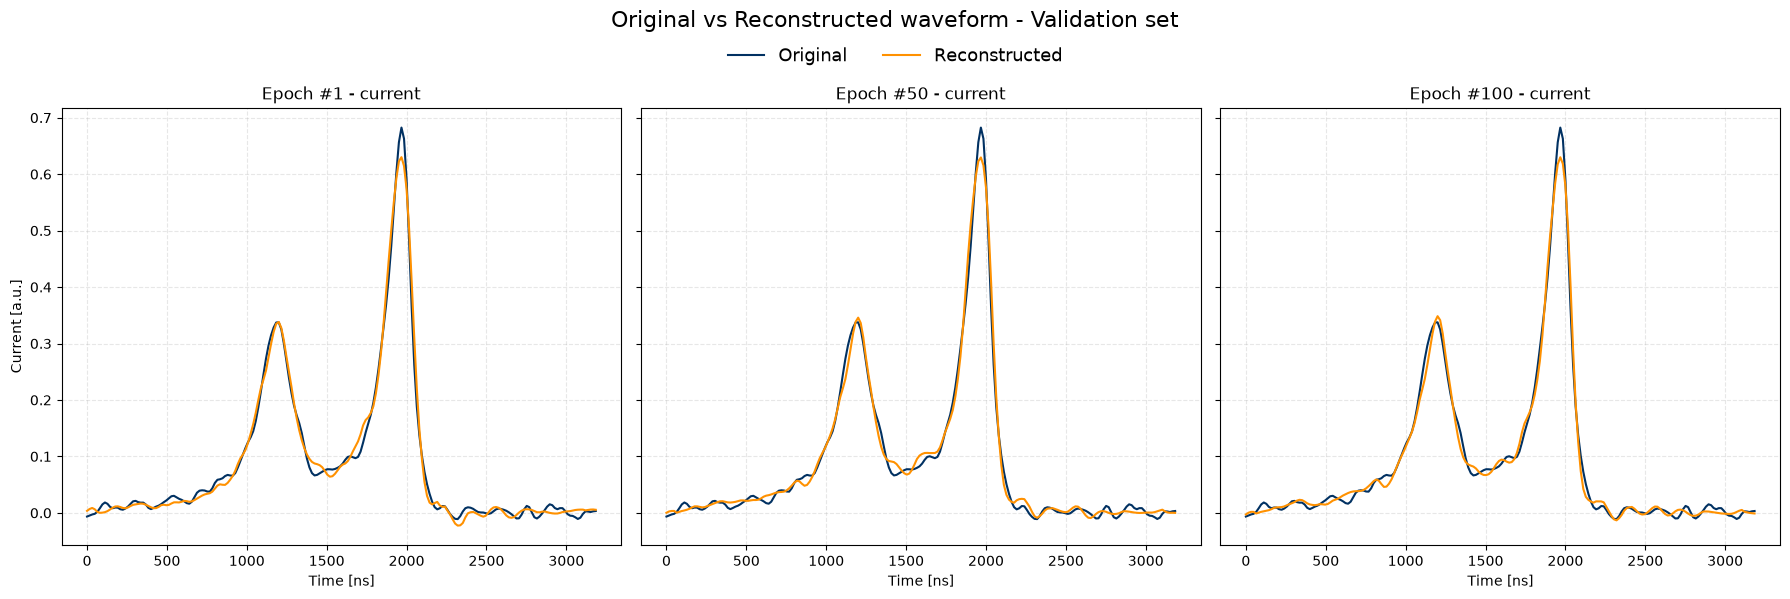

[cid, gamma=1000, 2 clusters] events that changed cluster with the training: 0.3276


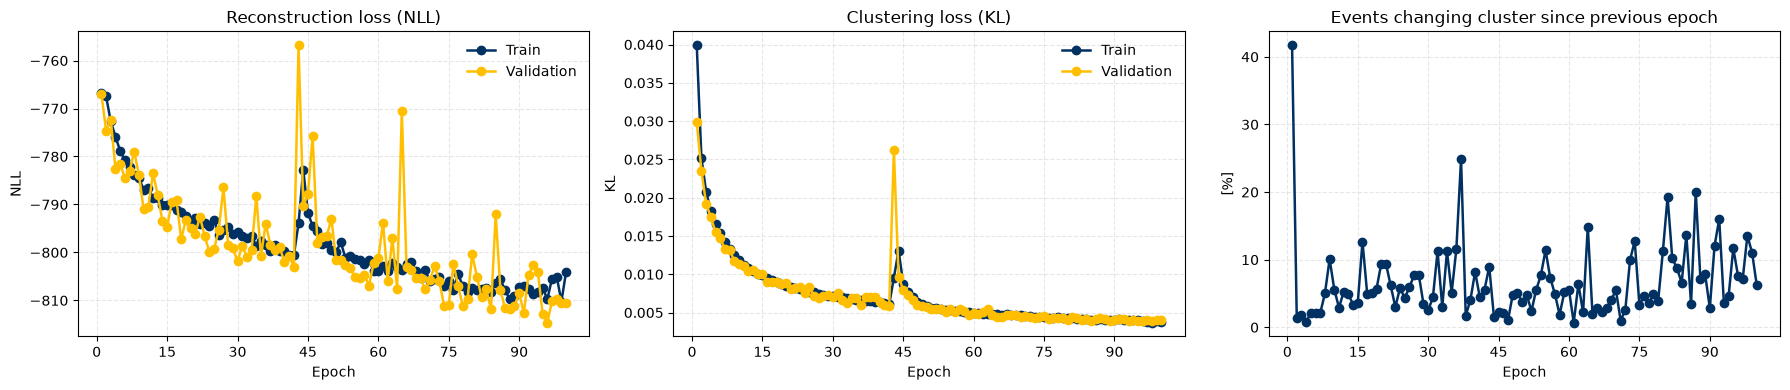

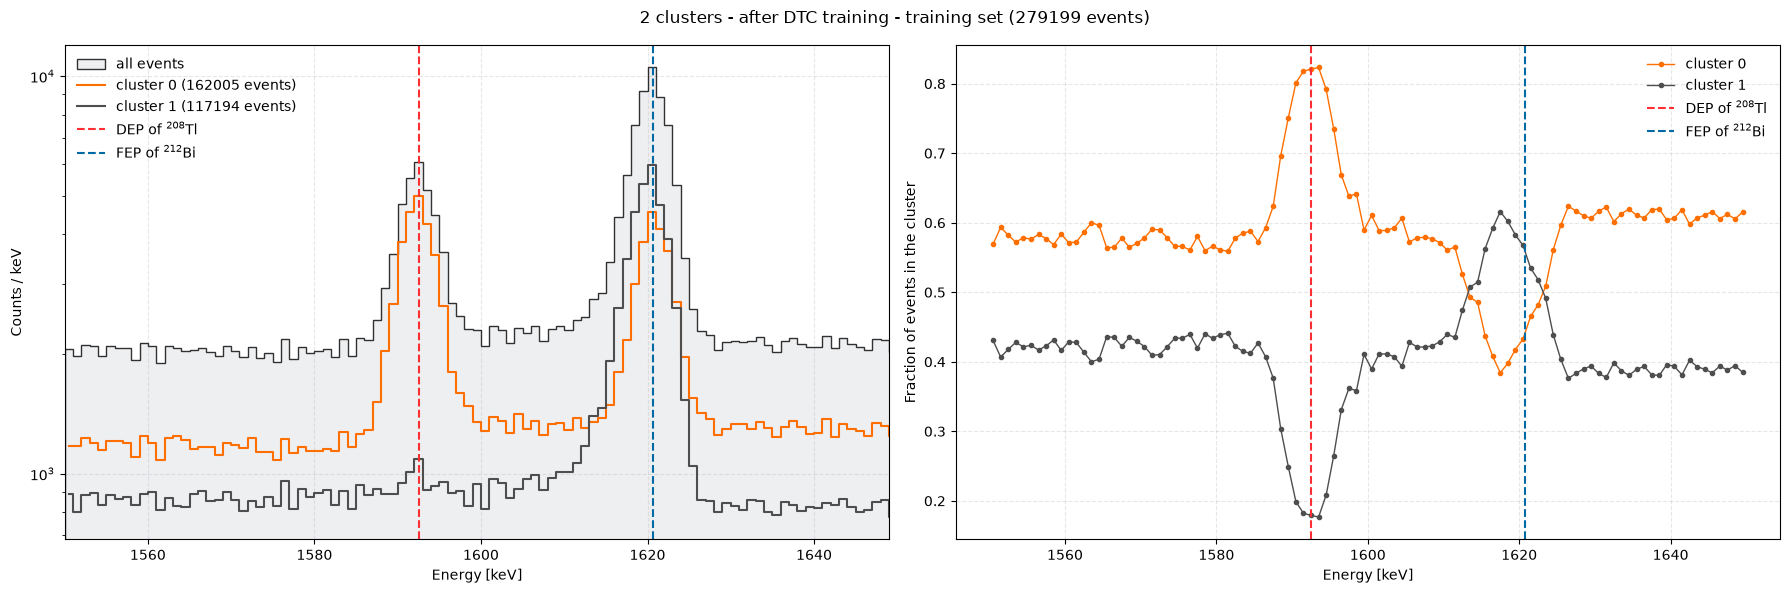

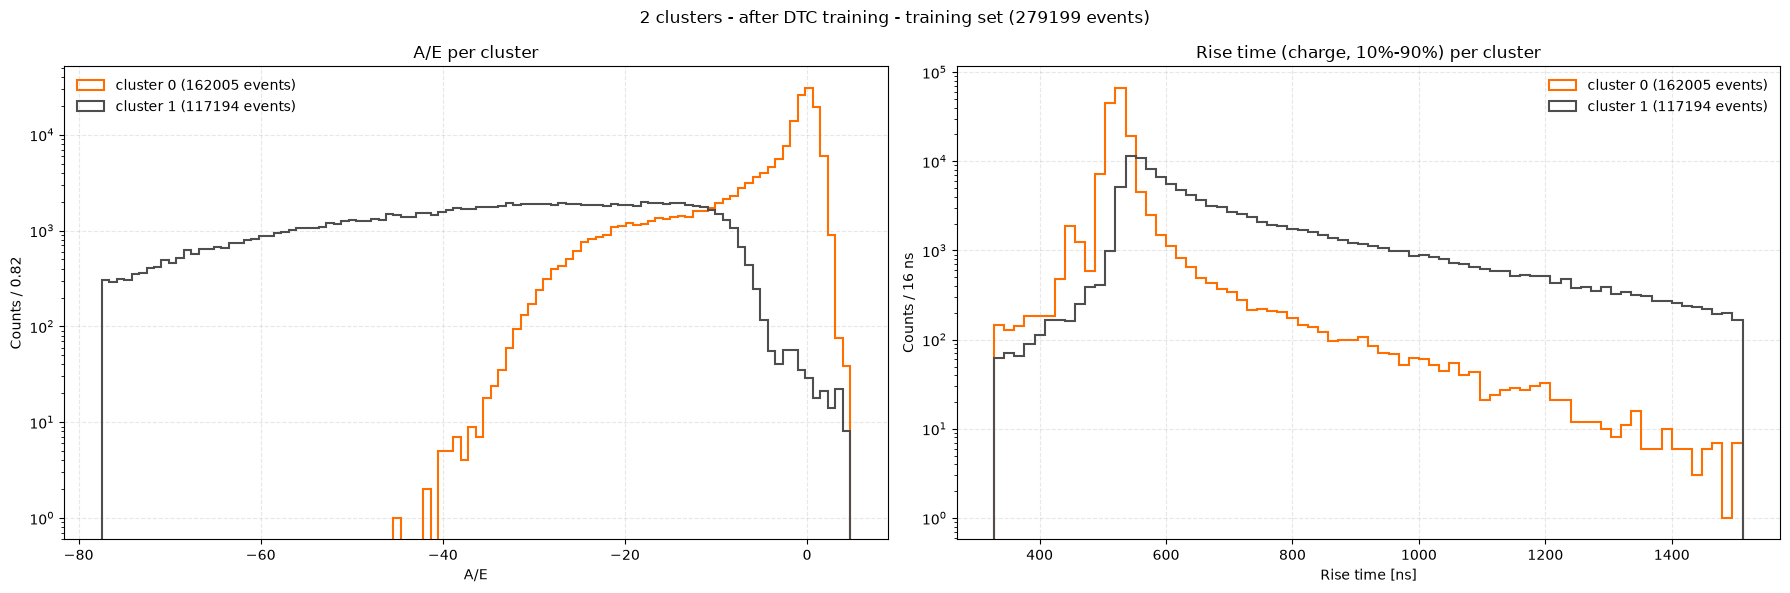

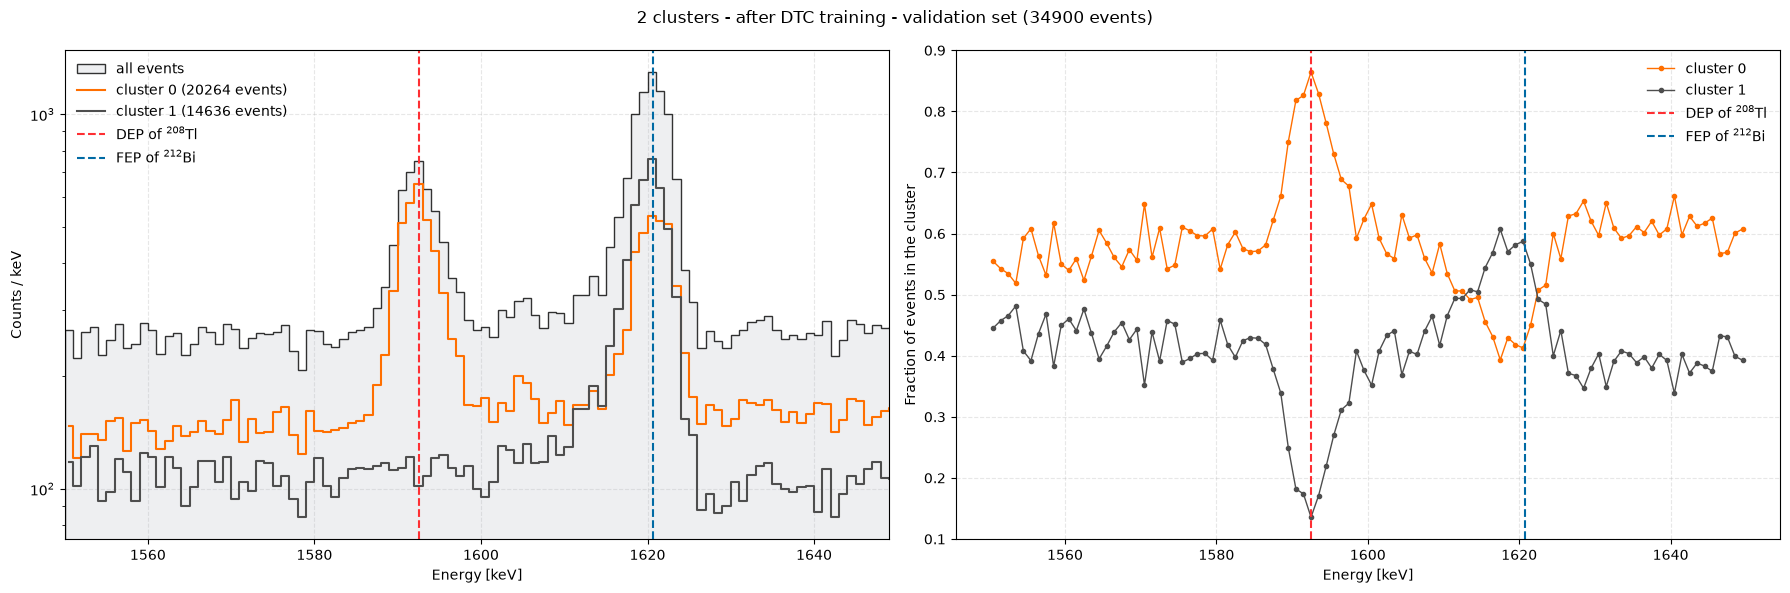

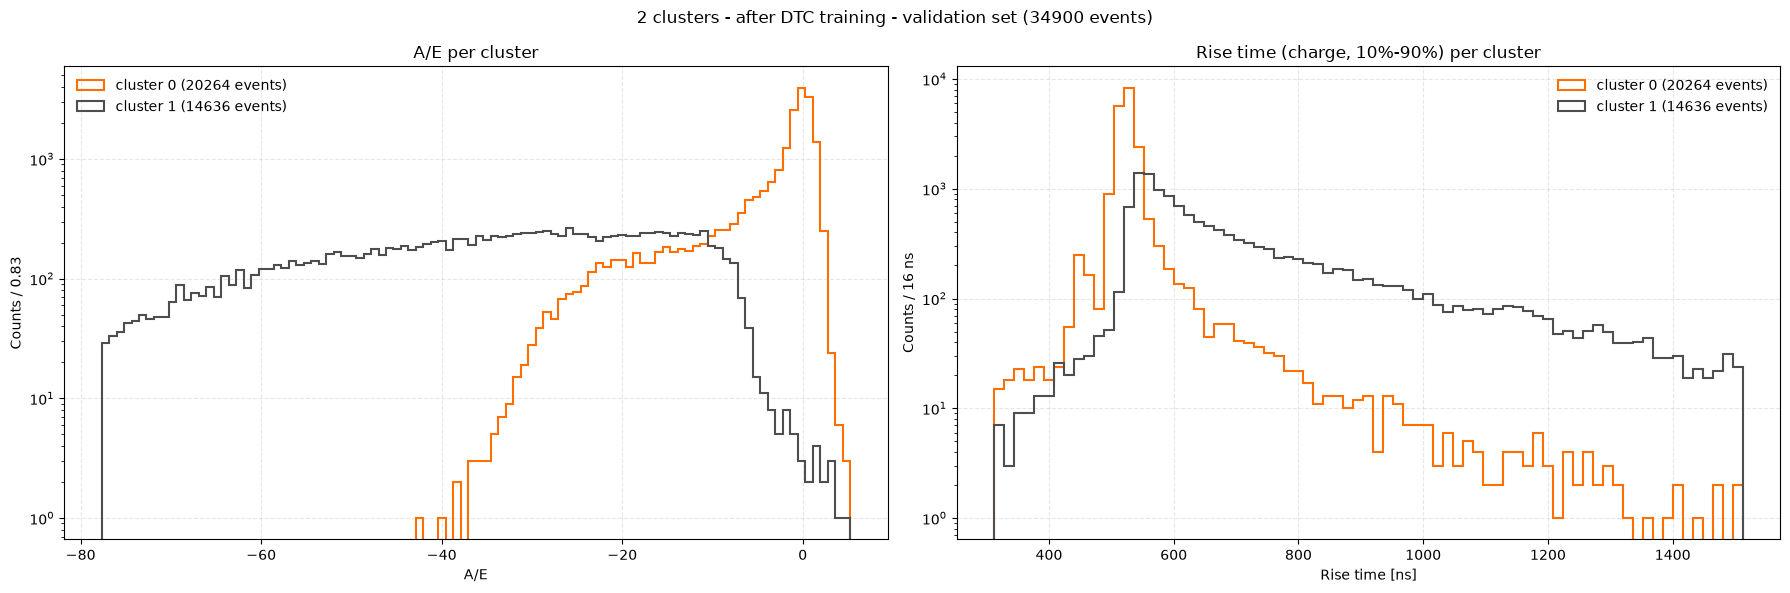

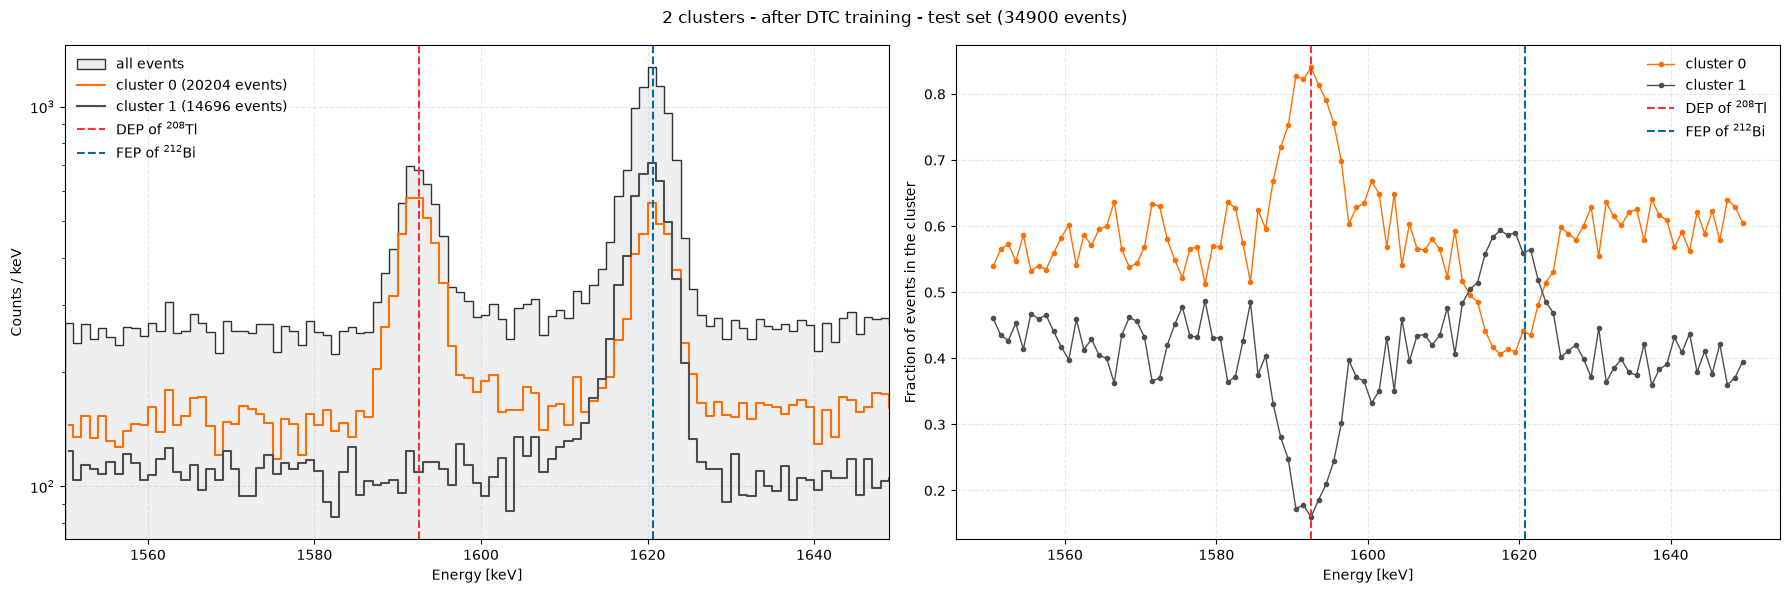

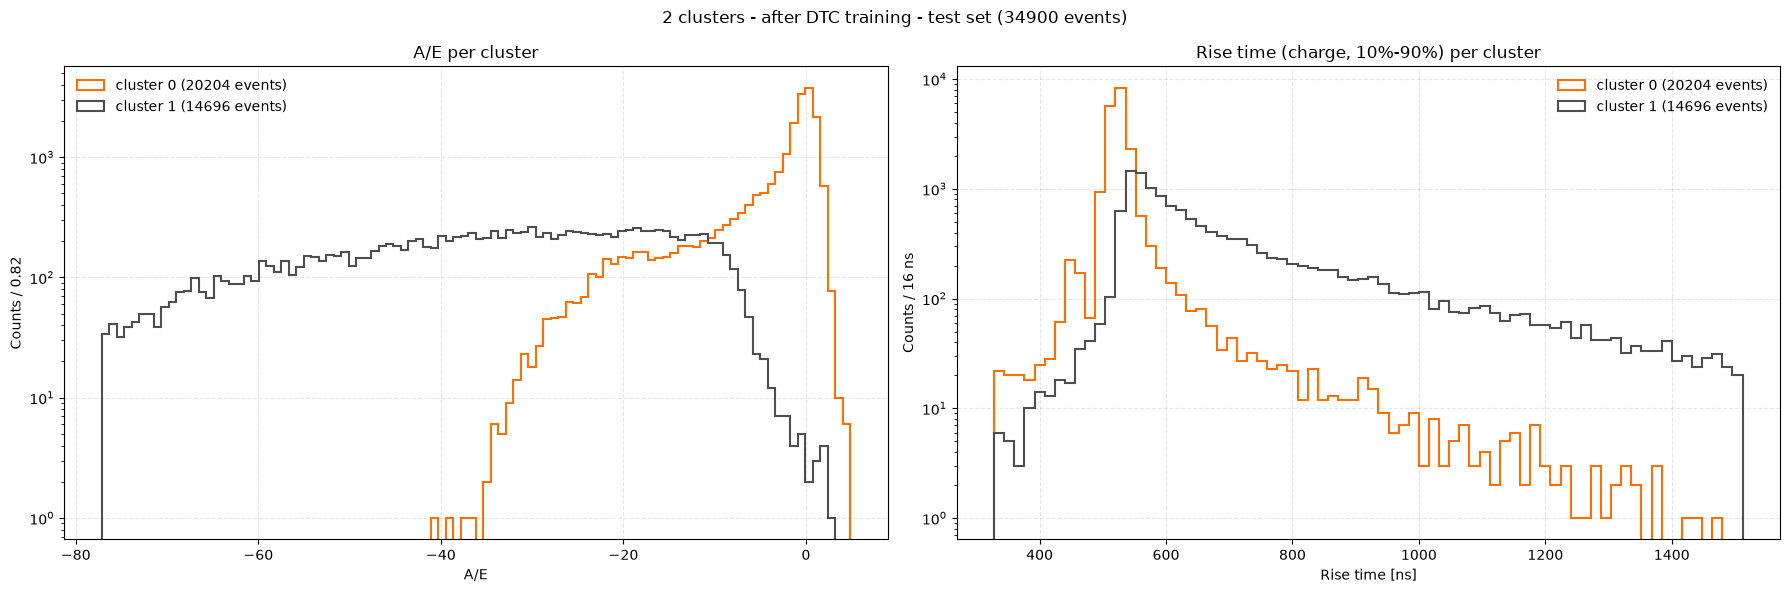

,total train,total validation,NLL train,NLL validation,KL train,KL validation,changes [%],events per cluster
epoch,,,,,,,,
1,-726.90,-737.10,-766.81,-766.99,0.04,0.03,41.72,0.49/0.51
2,-742.33,-751.14,-767.49,-774.64,0.03,0.02,1.34,0.47/0.53
3,-751.92,-753.12,-772.70,-772.33,0.02,0.02,1.78,0.49/0.51
4,-757.64,-765.20,-775.87,-782.65,0.02,0.02,0.85,0.50/0.50
5,-762.21,-765.96,-778.84,-781.47,0.02,0.02,2.12,0.52/0.48
...,...,...,...,...,...,...,...,...
96,-805.85,-810.80,-809.77,-814.63,0.00,0.00,7.64,0.57/0.43
97,-801.63,-806.08,-805.44,-810.12,0.00,0.00,7.12,0.49/0.51
98,-801.34,-805.86,-805.03,-809.78,0.00,0.00,13.54,0.63/0.37


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_cid_training_losses.csv | table_cid_training_losses.tex
cid: DEP per cluster [0.754 0.246] | FEP per cluster [0.459 0.541] -> SSE-like cluster = 0
saved: /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/dtc2_cid_gamma1000_100ep.pth | /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/dtc2_cid_gamma1000_100ep_bundle.pth


In [18]:
runs['cid'] = run_final('cid')

# 4. COMPARISON OF THE METRICS
Fraction of events kept by each metric (= events in its SSE-like cluster), in total and in the DEP and FEP windows, on every set.
A/E is available only on the whole calibration dataset (the events after the A/E cut are cleaned as a separate set).
Raw counts in the windows, no background subtraction: the same for every row, so the rows are comparable.

In [19]:
split_names = {'train': 'training', 'val': 'validation', 'test': 'test', 'all': 'whole dataset'}
rows = []
for tag, r in runs.items():
    keep = r['y'] == r['sse_cluster']
    for split in ('train', 'val', 'test', 'all'):
        idx = np.arange(len(energy)) if split == 'all' else data[f'idx_{split}']
        k, d, f = keep[idx], in_dep[idx], in_fep[idx]
        rows.append({'cut / set': f"{NAMES[tag]} / {split_names[split]}",
                     'kept [%]': 100 * k.mean(), 'DEP kept [%]': 100 * k[d].mean(), 'FEP kept [%]': 100 * k[f].mean()})

e_all, e_aoe = clean['energy_all'], clean['energy_AoE_all']
win = lambda e, p: np.abs(e - p[1]) <= 3 * p[2]
rows.append({'cut / set': 'A/E / whole dataset',
             'kept [%]': 100 * len(e_aoe) / len(e_all),
             'DEP kept [%]': 100 * win(e_aoe, dep).sum() / win(e_all, dep).sum(),
             'FEP kept [%]': 100 * win(e_aoe, fep).sum() / win(e_all, fep).sum()})
save_table(pd.DataFrame(rows).set_index('cut / set'), 'table_metrics_comparison')

,kept [%],DEP kept [%],FEP kept [%]
cut / set,,,
ACF / training,42.90,65.61,26.96
ACF / validation,42.94,66.49,27.06
ACF / test,42.93,66.19,27.24
ACF / whole dataset,42.91,65.75,27.00
Euclidean / training,42.64,65.13,27.06
Euclidean / validation,42.78,66.02,27.17
Euclidean / test,42.78,65.74,27.29
Euclidean / whole dataset,42.67,65.28,27.10
CID / training,58.02,75.25,45.88


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_metrics_comparison.csv | table_metrics_comparison.tex


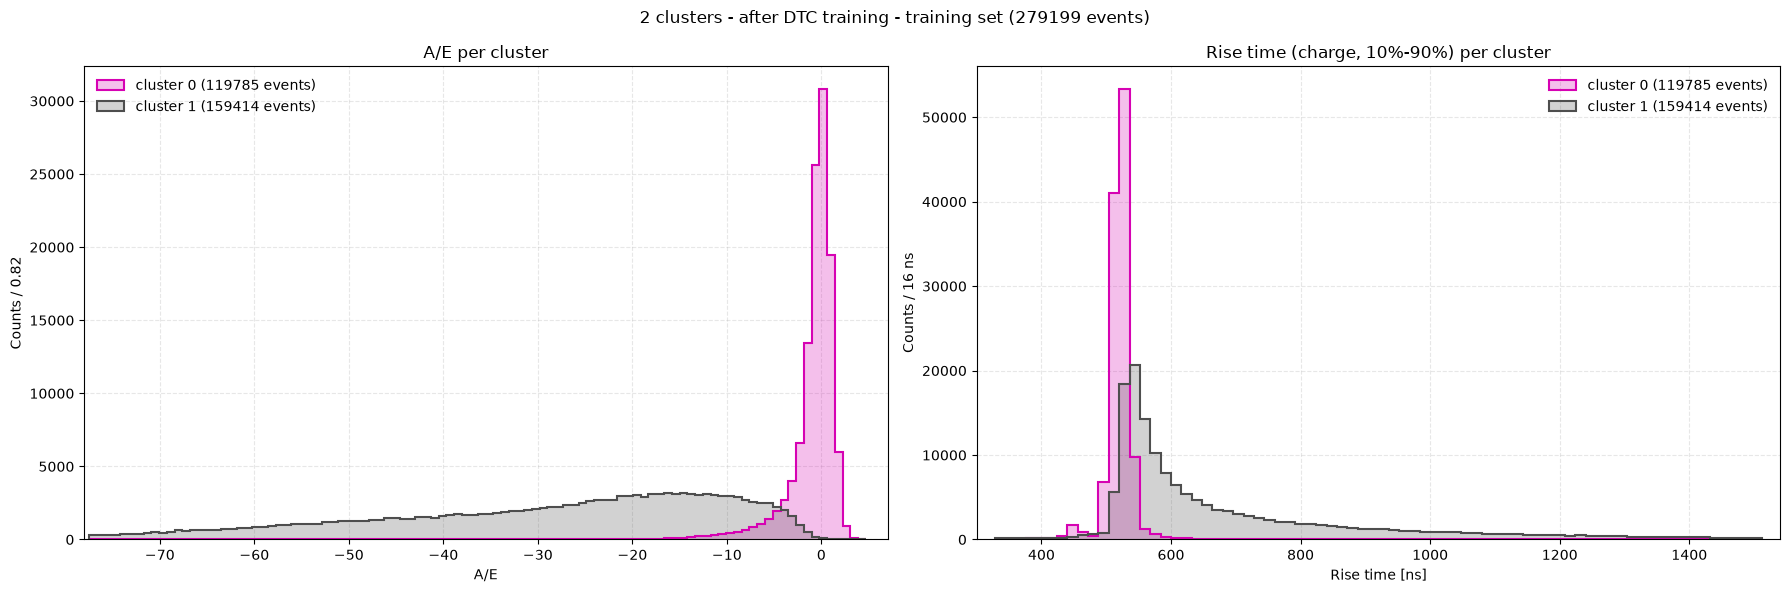

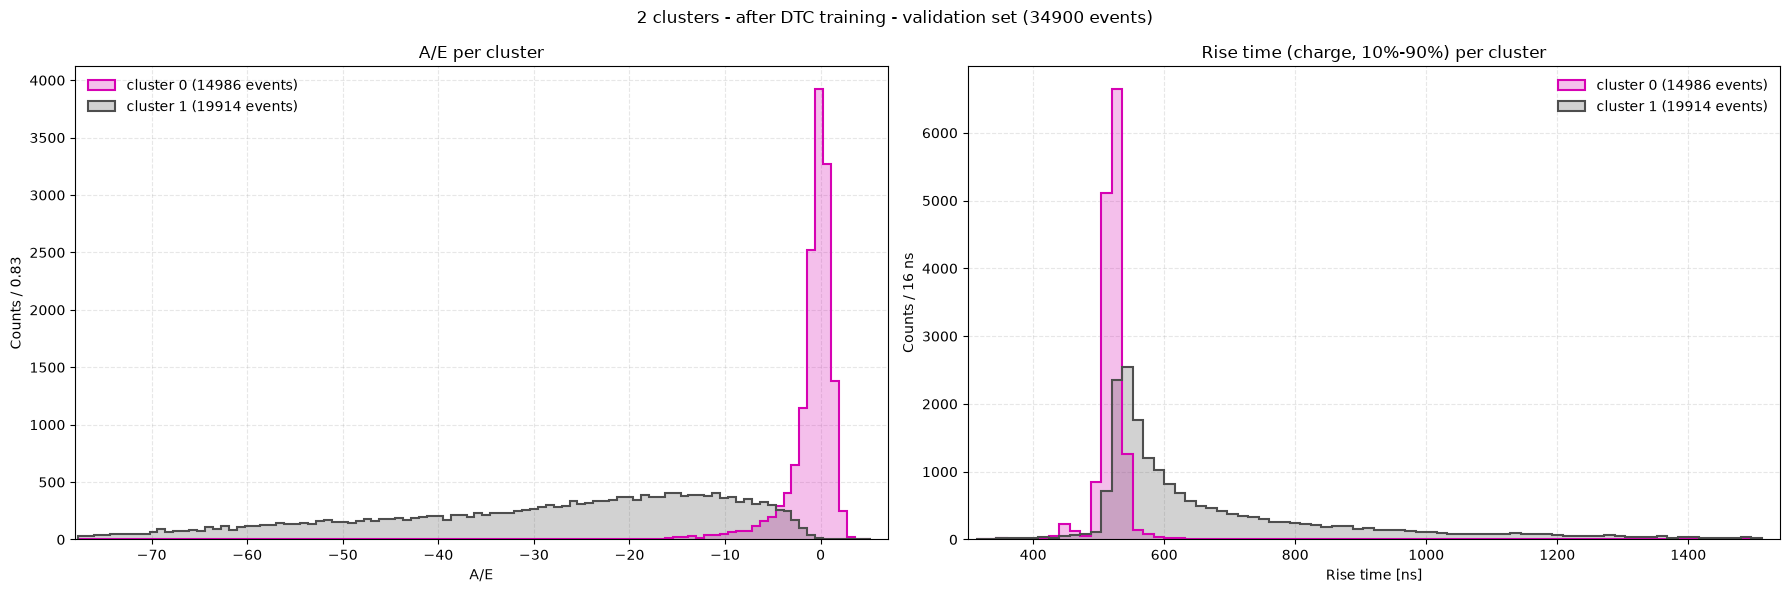

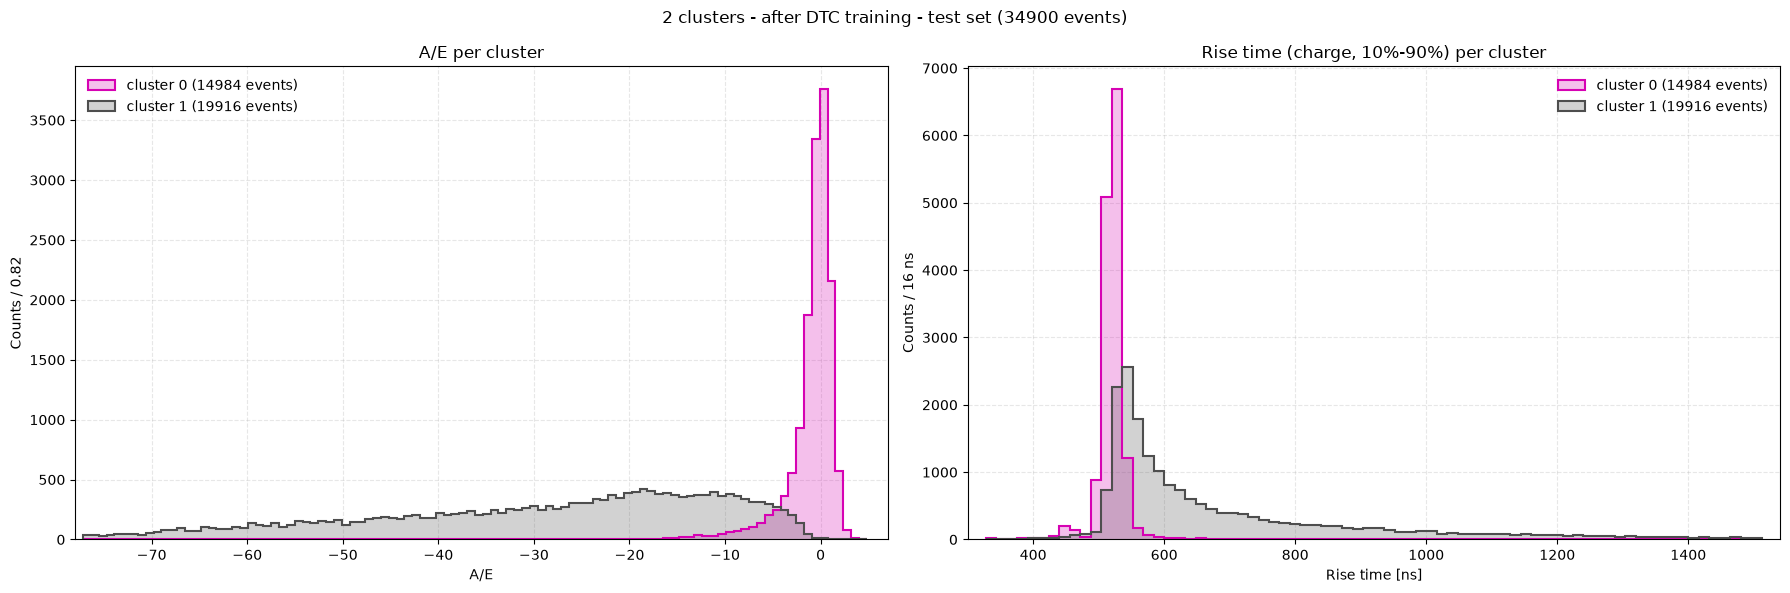

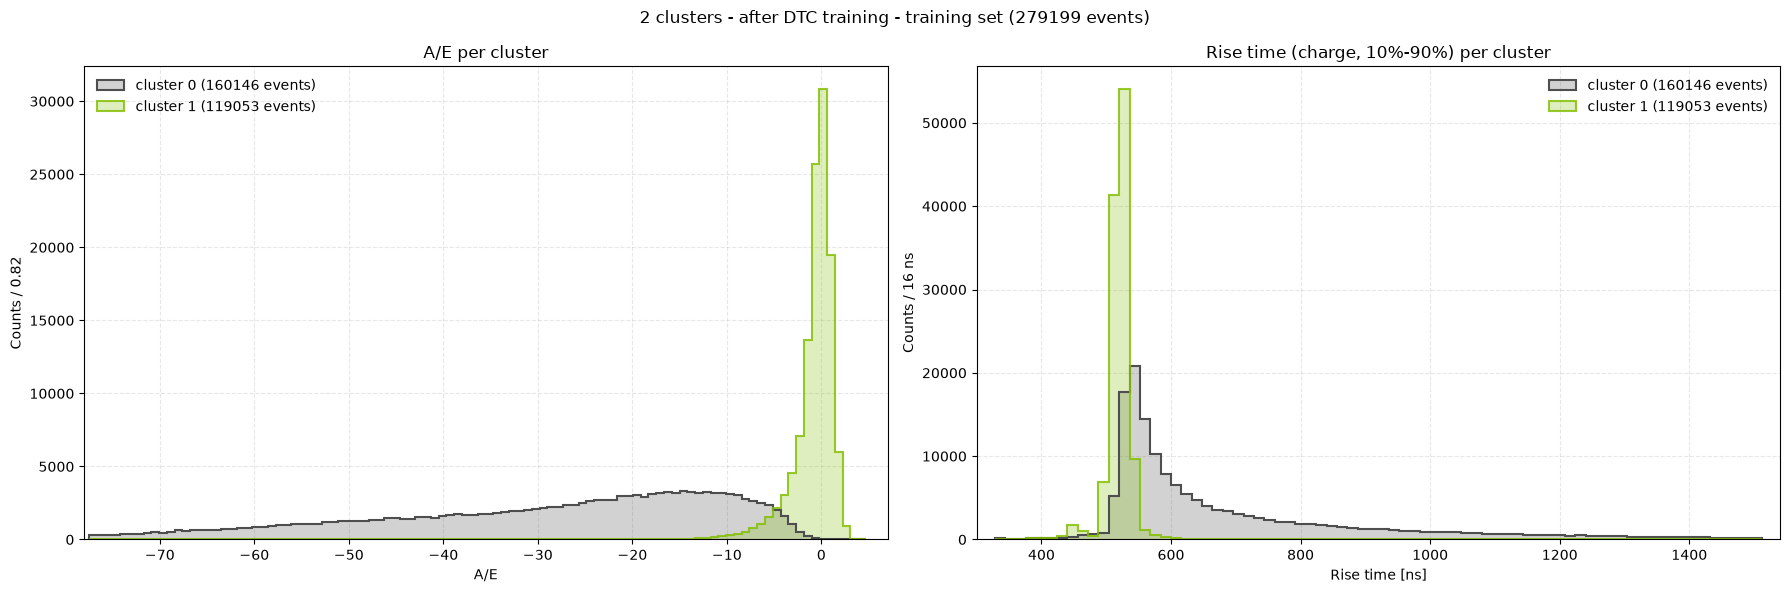

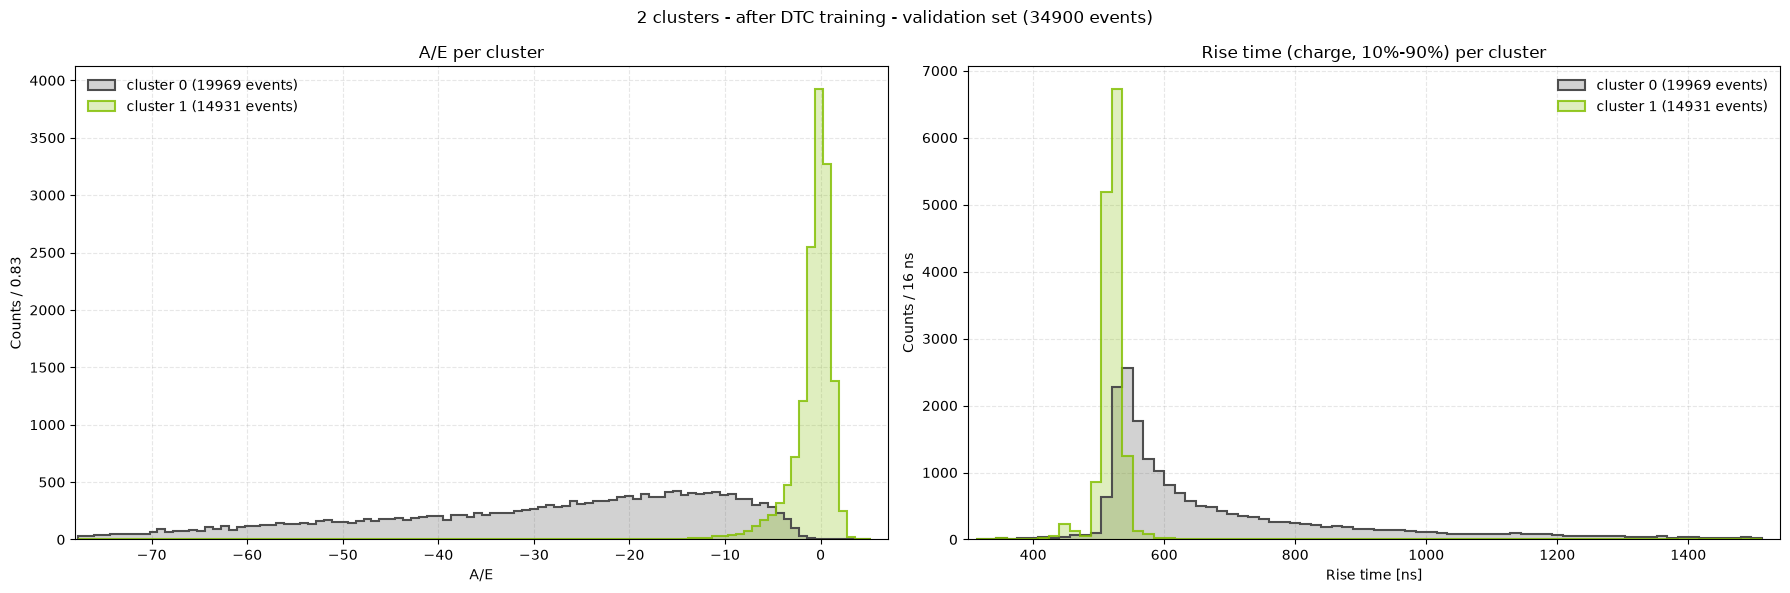

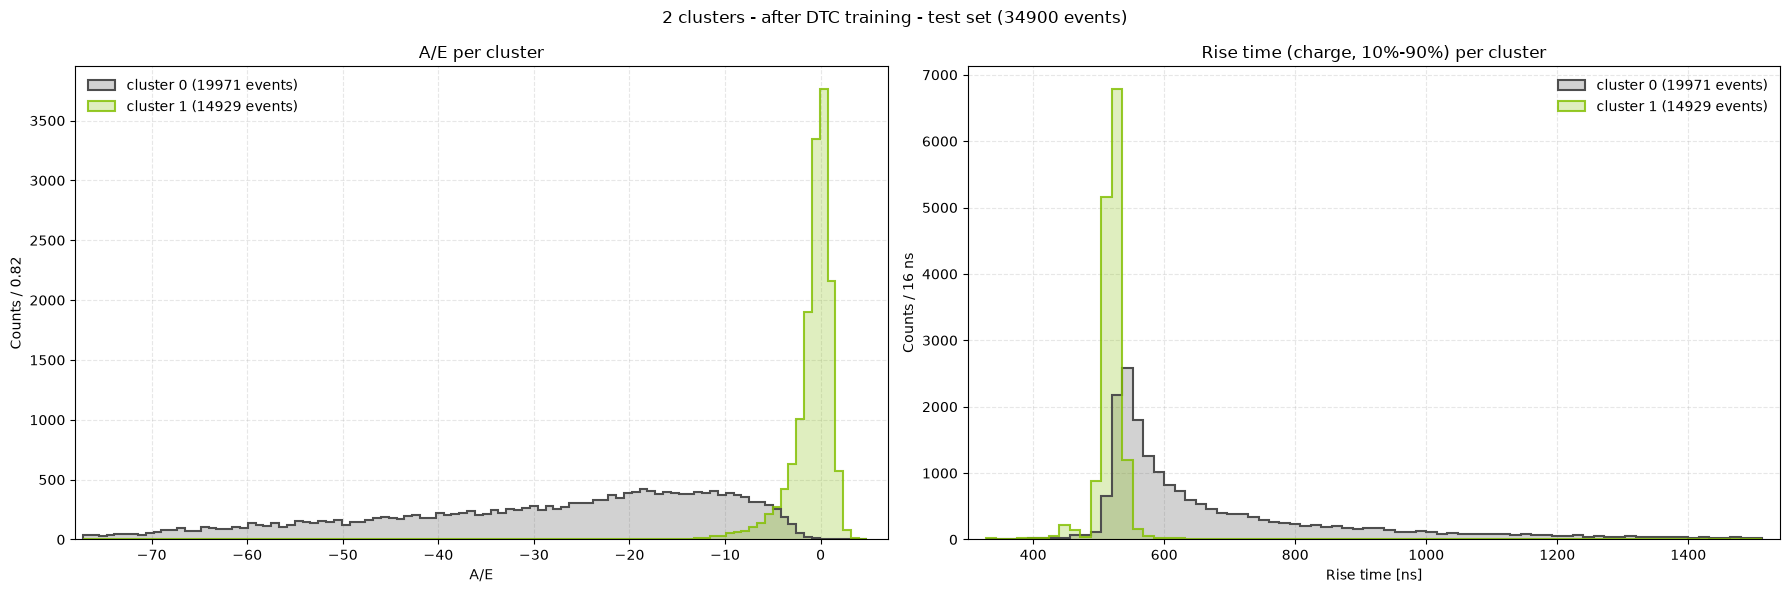

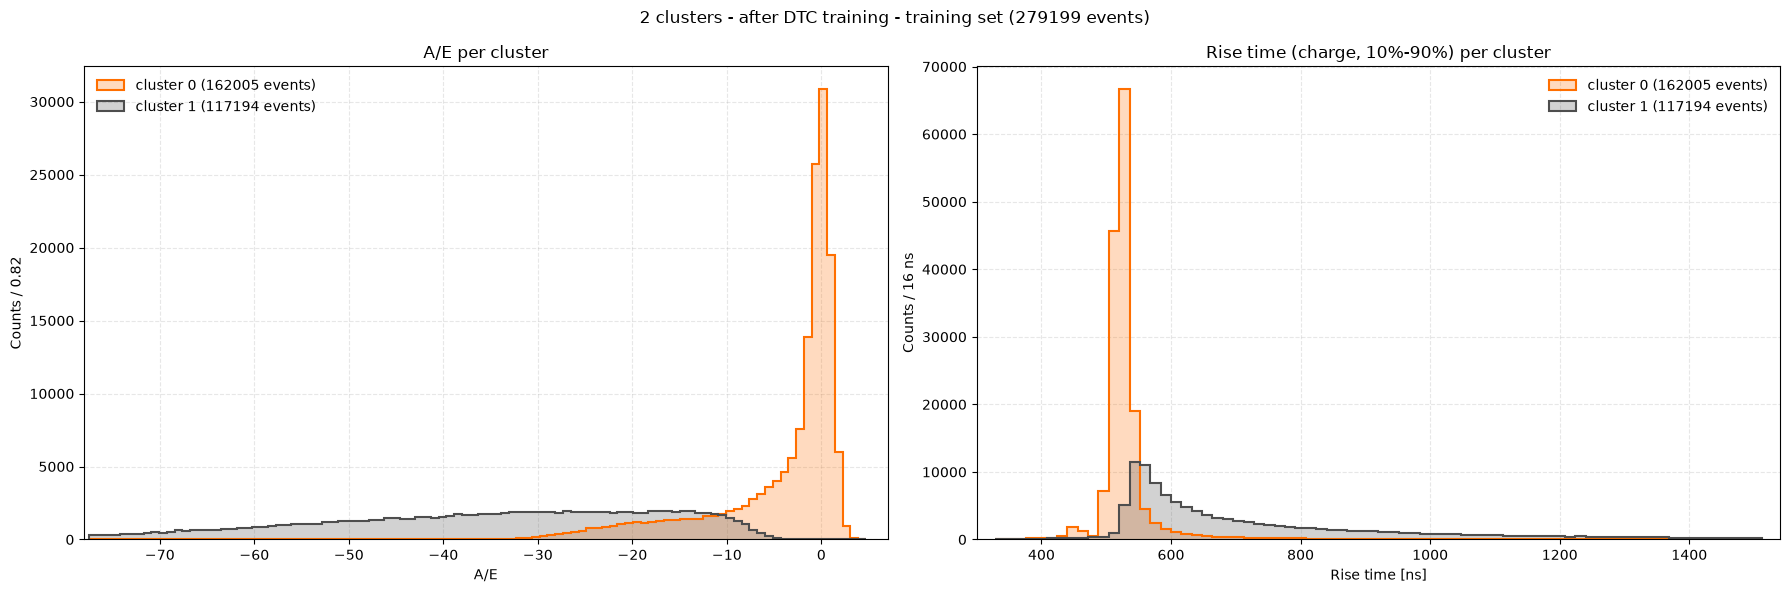

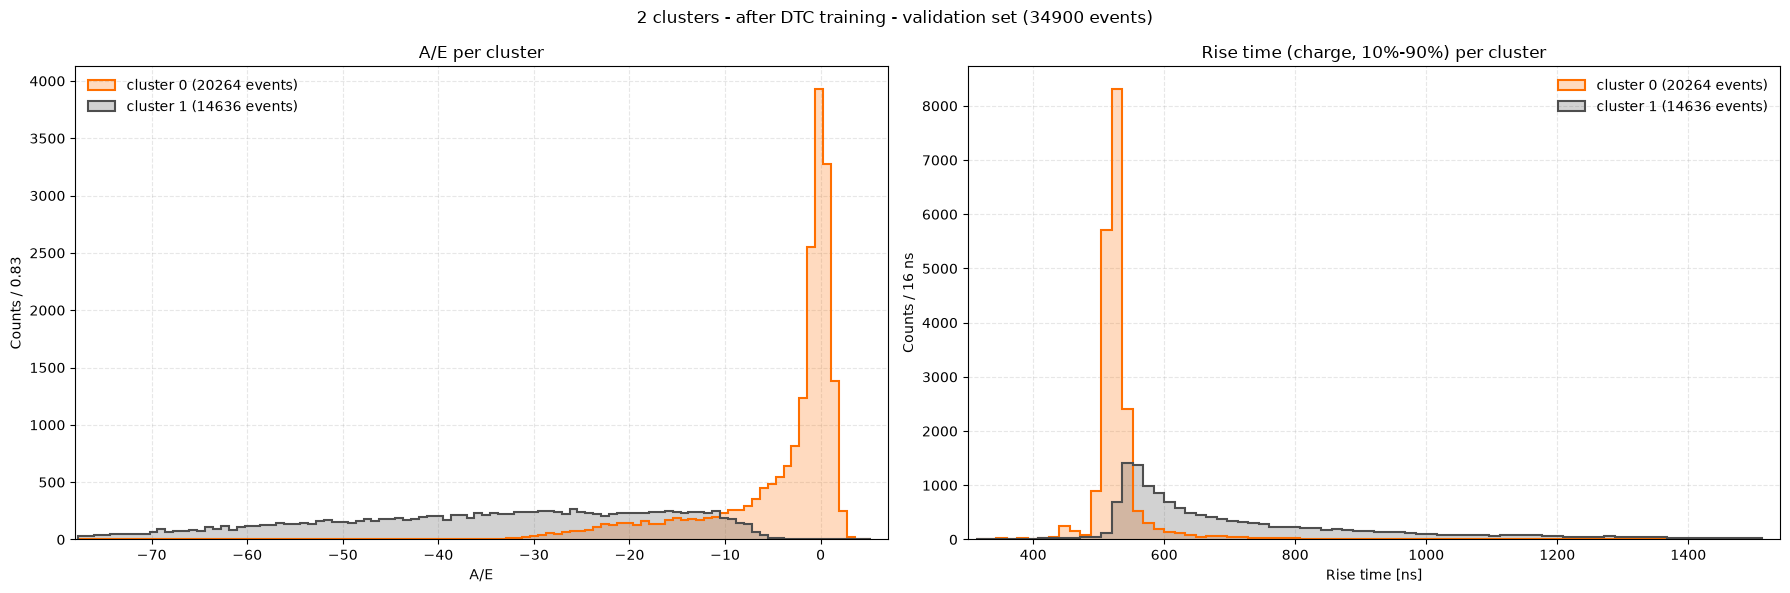

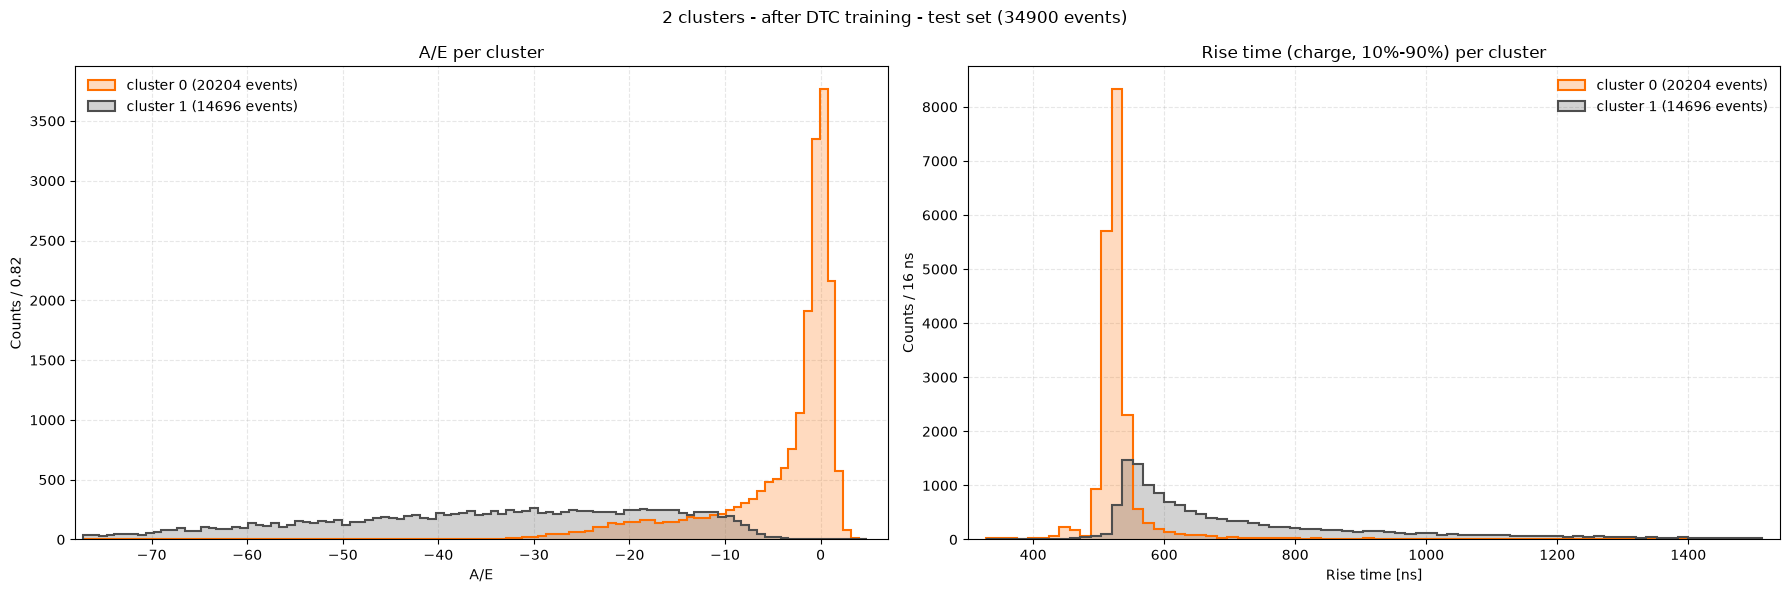

In [23]:
from matplotlib.patches import Patch
from matplotlib.colors import to_rgba

FILL_ALPHA = 0.25      # trasparenza del riempimento (i due cluster si sovrappongono)
# ---- A/E e rise time in scala LINEARE, per le tre metriche e i tre set ----
# Stessi istogrammi di pf.plot_cluster_variables (bin, colori, etichette), solo senza scala logaritmica.
# File: <metrica>_2cl_AoE_risetime_<set>_linear.pdf  (SUFFIX = '' per sovrascrivere quelli in scala log)
SUFFIX = '_linear'

# se il kernel è stato riavviato, 'runs' non c'è più: ricarico i modelli salvati e ricalcolo gli assegnamenti
# (servono solo le celle di import, PARAMETERS e PRELIMINARY, non i training)
if 'runs' not in globals() or not all(t in runs for t in METRICS):
    runs = {}
    for tag, metric in METRICS.items():
        ck = torch.load(os.path.join(OUT_DIR, f"dtc{N_CLUSTERS}_{metric}_gamma{GAMMA}_{TRAINING_EPOCHS}ep.pth"),
                        map_location="cpu", weights_only=True)
        model = DTC.DTC(input_length=data['waves'].shape[-1], pool_size=10, n_clusters=N_CLUSTERS,
                        distance_metric=metric, use_charge=use_charge)
        model.load_state_dict(ck['state_dict'])
        model.to(device)
        runs[tag] = dict(y=np.asarray(DTC.cluster_assignments(model, all_loader, device)),
                         sse_cluster=ck['sse_cluster'])
        print(f"{tag}: modello ricaricato, assegnamenti ricalcolati")


def plot_variables_linear(y, AoE, rise_time, n_clusters, title, name, colors):
    colors = pf._colors(colors, n_clusters)
    a_range = (np.nanquantile(AoE, 0.01), np.nanquantile(AoE, 0.99))
    r_range = (np.nanquantile(rise_time, 0.01), np.nanquantile(rise_time, 0.99))
    a_bins = np.linspace(*a_range, 101)
    r_bins = pf._risetime_bins(rise_time, r_range)

    fig, axes = pf.make_panels(2)
    handles = []
    for k in range(n_clusters):
        m = y == k
        a_k = AoE[m][np.isfinite(AoE[m])]
        r_k = rise_time[m][np.isfinite(rise_time[m])]
        for ax, vals, bins in ((axes[0], a_k, a_bins), (axes[1], r_k, r_bins)):
            if len(vals) > 0:
                ax.hist(vals, bins=bins, histtype='stepfilled', color=to_rgba(colors[k], FILL_ALPHA), lw=0)   # riempimento
                ax.hist(vals, bins=bins, histtype='step', color=colors[k], lw=1.5)                           # bordo
        if m.sum() > 0:
            # in legenda un solo rettangolo per cluster: interno trasparente + bordo pieno
            handles.append(Patch(facecolor=to_rgba(colors[k], FILL_ALPHA), edgecolor=colors[k], linewidth=1.5,
                                 label=f"cluster {k} ({m.sum()} events)"))

    axes[0].set_title("A/E per cluster")
    axes[0].set_xlabel("A/E")
    axes[1].set_title("Rise time (charge, 10%-90%) per cluster")
    axes[1].set_xlabel("Rise time [ns]")
    axes[0].set_ylabel(f"Counts / {a_bins[1] - a_bins[0]:.2g}")
    axes[1].set_ylabel(f"Counts / {r_bins[1] - r_bins[0]:.0f} ns")
    # axes[0].set_yscale('log')
    # axes[1].set_yscale('log')
    axes[0].set_xlim(-78, 7)
    axes[1].set_xlim(300, 1540)
    for ax in axes:
        ax.grid(alpha=0.3, ls='--')
        ax.set_axisbelow(True)
        ax.legend(handles=handles, frameon=False)

    fig.suptitle(title)
    plt.tight_layout()
    pf.save(fig, name)
    plt.show()
    
    
for tag in METRICS:
    pf.TAG, pf.PREFIX = tag, f"{tag}_"                       # colore della metrica e nome dei file
    y = runs[tag]['y']
    colors = pf.cluster_colors(y, energy, N_CLUSTERS)        # da TUTTI gli eventi, come nei grafici originali
    for split in ('train', 'val', 'test'):
        idx = data[f'idx_{split}']
        plot_variables_linear(y[idx], data['AoE'][idx], data['rise_time'][idx], N_CLUSTERS,
                              title=pf._title(N_CLUSTERS, split, len(idx)),
                              name=f"{N_CLUSTERS}cl_AoE_risetime_{split}{SUFFIX}", colors=colors)

# TEST LOSSES

ACF        test: total = -705.41   NLL = -781.35   KL = 0.0759
   riga LaTeX:  Test & -- & $-705.41$ & -- & $-781.35$ & -- & $0.0759$ \\
Euclidean  test: total = -731.40   NLL = -804.51   KL = 0.0731
   riga LaTeX:  Test & -- & $-731.40$ & -- & $-804.51$ & -- & $0.0731$ \\
CID        test: total = -807.28   NLL = -811.32   KL = 0.0040
   riga LaTeX:  Test & -- & $-807.28$ & -- & $-811.32$ & -- & $0.0040$ \\


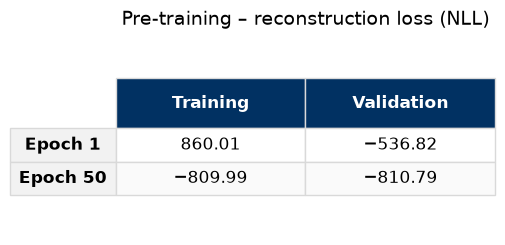

saved: /storage/rasera/DeepTemporalClusteringForL200/presentation/table_pretrain_losses.jpg


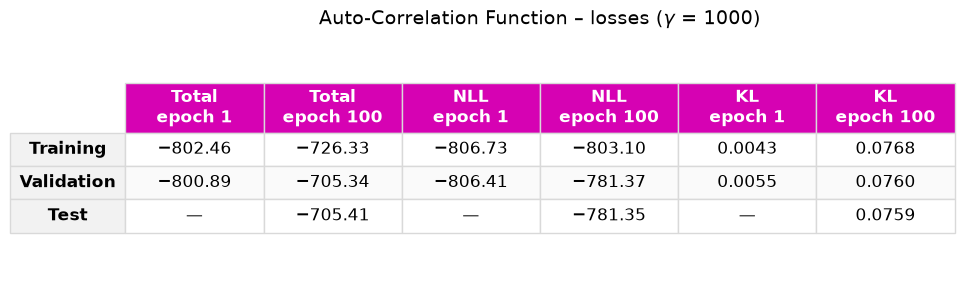

saved: /storage/rasera/DeepTemporalClusteringForL200/presentation/table_acf_losses.jpg


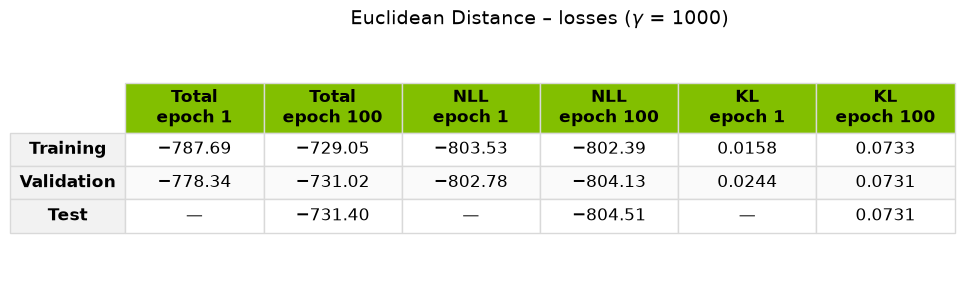

saved: /storage/rasera/DeepTemporalClusteringForL200/presentation/table_eucl_losses.jpg


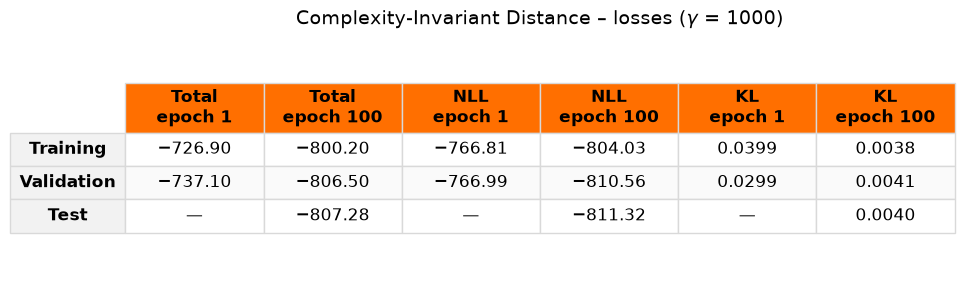

saved: /storage/rasera/DeepTemporalClusteringForL200/presentation/table_cid_losses.jpg


In [21]:
# ===== loss sul test dei modelli finali + tabelle per tesi (LaTeX) e presentazione (immagini) =====
# Dopo un riavvio: eseguire prima le celle di import, PARAMETERS e PRELIMINARY (non pretrain / training)
from torch.utils.data import TensorDataset, DataLoader
from matplotlib.colors import to_rgba

PRES_DIR   = "/storage/rasera/DeepTemporalClusteringForL200/presentation"   # immagini delle tabelle
IMG_FORMAT = 'jpg'                                                          # 'png' ha il testo più nitido
os.makedirs(PRES_DIR, exist_ok=True)

# ---------------- test set ----------------
idx_test = data['idx_test']
test_loader_ = DataLoader(TensorDataset(torch.as_tensor(data['waves'][idx_test], dtype=torch.float32),
                                        torch.zeros(len(idx_test))), batch_size=128, shuffle=False)


def load_final_model(tag):
    """Modello finale salvato in finalmodels/ (pesi dell'ultima epoca)."""
    metric = METRICS[tag]
    ck = torch.load(os.path.join(OUT_DIR, f"dtc{N_CLUSTERS}_{metric}_gamma{GAMMA}_{TRAINING_EPOCHS}ep.pth"),
                    map_location="cpu", weights_only=True)
    model = DTC.DTC(input_length=data['waves'].shape[-1], pool_size=10, n_clusters=N_CLUSTERS,
                    distance_metric=metric, use_charge=use_charge)
    model.load_state_dict(ck['state_dict'])
    return model.to(device)


def test_losses(model):
    """NLL e KL sul test set, come nel validation: per batch (p calcolata sul batch), poi media sui batch."""
    model.eval()
    nll, kl, n = 0.0, 0.0, 0
    with torch.no_grad():
        for w, _ in test_loader_:
            w = w.to(device)
            rec, q = model(w)
            p = DTC.tsc.target_distribution(q)
            nll += DTC.tae.nll_loss(rec, w, model.tae.logvar_obs).item()
            kl  += DTC.tsc.kl_loss(p, q).item()
            n += 1
    return nll / n, kl / n


# ---------------- calcolo + righe LaTeX del test ----------------
results = {}
for tag in METRICS:
    nll_te, kl_te = test_losses(load_final_model(tag))
    tot_te = nll_te + GAMMA * kl_te                     # stessa definizione del training
    results[tag] = dict(table=pd.read_csv(os.path.join(TABLE_DIR, f"table_{tag}_training_losses.csv"), index_col='epoch'),
                        test=(tot_te, nll_te, kl_te))
    print(f"{NAMES[tag]:10s} test: total = {tot_te:.2f}   NLL = {nll_te:.2f}   KL = {kl_te:.4f}")
    print(f"   riga LaTeX:  Test & -- & ${tot_te:.2f}$ & -- & ${nll_te:.2f}$ & -- & ${kl_te:.4f}$ \\\\")


# ---------------- tabelle come immagini ----------------
def fmt(v, d):
    return "—" if v is None else f"{v:.{d}f}".replace('-', '−')


def table_image(cells, col_labels, row_labels, title, filename, accent):
    r, g, b, _ = to_rgba(accent)
    head_text = 'white' if 0.299 * r + 0.587 * g + 0.114 * b < 0.55 else 'black'   # testo leggibile sul colore
    fig, ax = plt.subplots(figsize=(2.0 + 1.45 * len(col_labels), 0.9 + 0.55 * (len(cells) + 1)))
    ax.axis('off')
    tab = ax.table(cellText=cells, colLabels=col_labels, rowLabels=row_labels,
                   cellLoc='center', rowLoc='center', loc='center')
    tab.auto_set_font_size(False)
    tab.set_fontsize(12)
    tab.scale(1, 2.0)
    for (i, j), cell in tab.get_celld().items():
        cell.set_edgecolor('#d9d9d9')
        if i == 0:                                           # intestazione
            cell.set_facecolor(to_rgba(accent, 1.0))
            cell.set_text_props(color=head_text, fontweight='bold')
            cell.set_height(cell.get_height() * 1.5)
        elif j == -1:                                        # nomi delle righe
            cell.set_facecolor('#f2f2f2')
            cell.set_text_props(fontweight='bold')
        else:                                                # righe alternate
            cell.set_facecolor('white' if i % 2 else '#fafafa')
    ax.set_title(title, fontsize=14, pad=10)
    path = os.path.join(PRES_DIR, f"{filename}.{IMG_FORMAT}")
    fig.savefig(path, dpi=200, bbox_inches='tight',
                pil_kwargs={'quality': 95} if IMG_FORMAT in ('jpg', 'jpeg') else None)
    plt.show()
    print("saved:", path)


# pre-training: epoca 1 e ultima, training e validation
pre = pd.read_csv(os.path.join(TABLE_DIR, 'table_pretrain_losses.csv'), index_col='epoch')
table_image([[fmt(pre['NLL train'].iloc[0], 2),  fmt(pre['NLL validation'].iloc[0], 2)],
             [fmt(pre['NLL train'].iloc[-1], 2), fmt(pre['NLL validation'].iloc[-1], 2)]],
            col_labels=['Training', 'Validation'],
            row_labels=['Epoch 1', f'Epoch {len(pre)}'],
            title="Pre-training – reconstruction loss (NLL)",
            filename="table_pretrain_losses", accent=pf.color2)

# training finali: una tabella per metrica, nel colore della metrica
E = TRAINING_EPOCHS
cols = [f"{q}\nepoch {e}" for q in ('Total', 'NLL', 'KL') for e in (1, E)]
full_names = {'acf': 'Auto-Correlation Function', 'eucl': 'Euclidean Distance', 'cid': 'Complexity-Invariant Distance'}
for tag in METRICS:
    t, (tot_te, nll_te, kl_te) = results[tag]['table'], results[tag]['test']
    first, last = t.iloc[0], t.iloc[-1]
    cells = [[fmt(first['total train'], 2), fmt(last['total train'], 2), fmt(first['NLL train'], 2),
              fmt(last['NLL train'], 2), fmt(first['KL train'], 4), fmt(last['KL train'], 4)],
             [fmt(first['total validation'], 2), fmt(last['total validation'], 2), fmt(first['NLL validation'], 2),
              fmt(last['NLL validation'], 2), fmt(first['KL validation'], 4), fmt(last['KL validation'], 4)],
             [fmt(None, 2), fmt(tot_te, 2), fmt(None, 2), fmt(nll_te, 2), fmt(None, 4), fmt(kl_te, 4)]]
    table_image(cells, cols, ['Training', 'Validation', 'Test'],
                title=f"{full_names[tag]} – losses ($\\gamma$ = {GAMMA})",
                filename=f"table_{tag}_losses", accent=pf.METRIC_COLORS[tag])

In [22]:
# ===== percentuale di eventi per cluster in due finestre di energia =====
# Dopo un riavvio: eseguire prima le celle di import, PARAMETERS e PRELIMINARY
WINDOWS = {'1592-1593 keV': (1592.0, 1593.0), '1620.5-1621.5 keV': (1620.5, 1621.5)}

energy = data['energy']
sets = {'training': data['idx_train'], 'validation': data['idx_val'], 'test': data['idx_test'],
        'whole dataset': np.arange(len(energy))}

rows = []
for tag, metric in METRICS.items():
    ck = torch.load(os.path.join(OUT_DIR, f"dtc{N_CLUSTERS}_{metric}_gamma{GAMMA}_{TRAINING_EPOCHS}ep.pth"),
                    map_location="cpu", weights_only=True)
    model = DTC.DTC(input_length=data['waves'].shape[-1], pool_size=10, n_clusters=N_CLUSTERS,
                    distance_metric=metric, use_charge=use_charge)
    model.load_state_dict(ck['state_dict'])
    y = np.asarray(DTC.cluster_assignments(model.to(device), all_loader, device))

    for set_name, idx in sets.items():
        e, yy = energy[idx], y[idx]
        for w_name, (lo, hi) in WINDOWS.items():
            m = (e >= lo) & (e < hi)
            row = {'metric': NAMES[tag], 'set': set_name, 'window': w_name, 'events': int(m.sum())}
            for k in range(N_CLUSTERS):
                row[f'cluster {k} [%]'] = 100 * (yy[m] == k).mean()
            rows.append(row)

table_windows = pd.DataFrame(rows).set_index(['metric', 'set', 'window'])
display(table_windows.round(2))

events  cluster 0 [%]  \
metric    set           window                                     
ACF       training      1592-1593 keV        6066          74.99   
                        1620.5-1621.5 keV    9822          23.45   
          validation    1592-1593 keV         752          78.46   
                        1620.5-1621.5 keV    1216          22.37   
          test          1592-1593 keV         682          75.22   
                        1620.5-1621.5 keV    1227          22.82   
          whole dataset 1592-1593 keV        7500          75.36   
                        1620.5-1621.5 keV   12265          23.28   
Euclidean training      1592-1593 keV        6066          24.96   
                        1620.5-1621.5 keV    9822          76.29   
          validation    1592-1593 keV         752          22.47   
                        1620.5-1621.5 keV    1216          77.55   
          test          1592-1593 keV         682          24.49   
                        1620.5-1621.5 keV    1227          76.45   
          whole dataset 1592-1593 keV        7500          24.67   
                        1620.5-1621.5 keV   12265          76.43   
CID       training      1592-1593 keV        6066          82.10   
                        1620.5-1621.5 keV    9822          44.63   
          validation    1592-1593 keV         752          86.44   
                        1620.5-1621.5 keV    1216          44.00   
          test          1592-1593 keV         682          84.02   
                        1620.5-1621.5 keV    1227          44.58   
          whole dataset 1592-1593 keV        7500          82.71   
                        1620.5-1621.5 keV   12265          44.57   

                                           cluster 1 [%]  
metric    set           window                            
ACF       training      1592-1593 keV              25.01  
                        1620.5-1621.5 keV          76.55  
          validation    1592-1593 keV              21.54  
                        1620.5-1621.5 keV          77.63  
          test          1592-1593 keV              24.78  
                        1620.5-1621.5 keV          77.18  
          whole dataset 1592-1593 keV              24.64  
                        1620.5-1621.5 keV          76.72  
Euclidean training      1592-1593 keV              75.04  
                        1620.5-1621.5 keV          23.71  
          validation    1592-1593 keV              77.53  
                        1620.5-1621.5 keV          22.45  
          test          1592-1593 keV              75.51  
                        1620.5-1621.5 keV          23.55  
          whole dataset 1592-1593 keV              75.33  
                        1620.5-1621.5 keV          23.57  
CID       training      1592-1593 keV              17.90  
                        1620.5-1621.5 keV          55.37  
          validation    1592-1593 keV              13.56  
                        1620.5-1621.5 keV          56.00  
          test          1592-1593 keV              15.98  
                        1620.5-1621.5 keV          55.42  
          whole dataset 1592-1593 keV              17.29  
                        1620.5-1621.5 keV          55.43